# **Laboratorio #2 – Parte B: Segmentación Semántica con U-Net y Transfer Learning**

### **Estudiante:** Luis Alejandro Castrillón Pulgarín - 1000330339  


In [1]:
import os 
import sys  
import time  
import json 
import shutil
import random
import pathlib 
import warnings 
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from scipy import ndimage
from scipy.spatial.distance import directed_hausdorff
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision import models
import torchvision.transforms.functional as TF
from IPython.display import display
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# Funcion para fijar la semilla aleatoria en todas las librerias y asegurar reproducibilidad
def set_seed(seed=42): 
    random.seed(seed) 
    np.random.seed(seed) 
    torch.manual_seed(seed) 
    torch.cuda.manual_seed_all(seed)


set_seed(42) 
torch.backends.cudnn.benchmark = True 

# Centraliza las rutas de trabajo mediante pathlib.Path para maxima portabilidad
BASE_DIR = pathlib.Path(".").resolve()
IMAGES_DIR = BASE_DIR / "images"
TRIMAPS_DIR = BASE_DIR / "annotations" / "trimaps"
SPLITS_DIR = BASE_DIR / "annotations"

# Crea los directorios de salida organizados para modelos, figuras, metricas y TensorBoard
OUTPUT_DIR = BASE_DIR / "outputs_parte_b"  
MODEL_DIR = OUTPUT_DIR / "models"  
FIGURE_DIR = OUTPUT_DIR / "figures"
METRIC_DIR = OUTPUT_DIR / "metrics" 
RUNS_DIR = OUTPUT_DIR / "runs"

# Itera sobre las carpetas de salida y las crea si no existen en el disco
for d in [MODEL_DIR, FIGURE_DIR, METRIC_DIR, RUNS_DIR]: 
    d.mkdir(parents=True, exist_ok=True) 

# Constantes globales de configuracion
IMG_SIZE = 256
BATCH_SIZE = 8 
EPOCHS = 5
N_TRAIN = 1200 

# Dispositivo de aceleracion automatico
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  
USE_AMP = device.type == "cuda" 
RESULTS_PATH = METRIC_DIR / "final_results.json"
RESULTS = {}
if RESULTS_PATH.exists():
    with RESULTS_PATH.open("r") as f:
        loaded_results = json.load(f)
    if not isinstance(loaded_results, dict):
        raise TypeError(f"El archivo de resultados debe contener un objeto JSON: {RESULTS_PATH}")
    RESULTS.update(loaded_results)

def restore_model_results_from_csv():
    model_keys = {"M1", "M2", "M3", "R1", "R2", "R4"}
    metric_columns = {
        "iou": ("Test IoU",),
        "dice": ("Test Dice Score", "Test Dice"),
        "acc": ("Accuracy (Píxel)", "Accuracy"),
        "precision": ("Precisión",),
        "recall": ("Recall",),
    }
    csv_sources = (("tabla_actividad7.csv", "Modelo"), ("resumen_experimentos.csv", "Experimento"))
    for filename, key_column in csv_sources:
        csv_path = METRIC_DIR / filename
        if not csv_path.exists():
            continue
        for row in pd.read_csv(csv_path).to_dict(orient="records"):
            key = row.get(key_column)
            if key not in model_keys:
                continue
            result = RESULTS.setdefault(key, {})
            test = result.setdefault("test", {})
            for metric, columns in metric_columns.items():
                for column in columns:
                    value = row.get(column)
                    if value is not None and pd.notna(value):
                        test.setdefault(metric, float(value))
                        break
            time_value = row.get("Tiempo Total (s)")
            if time_value is None or pd.isna(time_value):
                time_value = row.get("Tiempo (s)")
            if time_value is not None and pd.notna(time_value):
                result.setdefault("time", float(time_value))
            params = row.get("Parámetros Entrenables")
            if params is not None and pd.notna(params):
                result.setdefault("params_trainable", int(str(params).replace(",", "")))

restore_model_results_from_csv()
COLORS = {"M1": "#C44E52", "M2": "#DD8452", "M3": "#55A868", "R1": "#8172B2", "R2": "#937860", "R4": "#4C72B0"} 

# Funcion auxiliar para guardar figuras en disco
def save_fig(name):  
    plt.savefig(FIGURE_DIR / name, dpi=110, bbox_inches="tight") 

# Funcion auxiliar para guardar los resultados en JSON
def save_results():  
    with RESULTS_PATH.open("w") as f:  
        json.dump(RESULTS, f, indent=2)

save_results()  # Persistir resultados recuperados desde JSON/CSV
print(f"Experimentos con resultados restaurados: {sorted(k for k in RESULTS if k in {'M1', 'M2', 'M3', 'R1', 'R2', 'R4'})}")

print(f"Versión de Python           : {sys.version.split()[0]}")
print(f"Versión de PyTorch          : {torch.__version__}")  
print(f"Versión de torchvision      : {torchvision.__version__}")  
print(f"Disponibilidad de CUDA      : {torch.cuda.is_available()}")  
if device.type == "cuda":
    print(f"Nombre de la GPU            : {torch.cuda.get_device_name(0)}")  
    print(f"Memoria VRAM Total          : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB") 
print(f"Dispositivo Seleccionado    : {device} (AMP: {USE_AMP})")  
print(f"Carpeta de Imágenes RGB    : {IMAGES_DIR.exists()} -> {IMAGES_DIR.name}/") 
print(f"Carpeta de Mascaras Trimap : {TRIMAPS_DIR.exists()} -> annotations/{TRIMAPS_DIR.name}/")
print(f"Configuración Global        : IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, N_TRAIN={N_TRAIN}, TEST_SET=official_full") 

Experimentos con resultados restaurados: ['M1', 'M2', 'M3', 'R1', 'R2', 'R4']
Versión de Python           : 3.14.7
Versión de PyTorch          : 2.14.0+cu126
Versión de torchvision      : 0.29.0+cu126
Disponibilidad de CUDA      : True
Nombre de la GPU            : NVIDIA GeForce RTX 3050 Laptop GPU
Memoria VRAM Total          : 3.80 GB
Dispositivo Seleccionado    : cuda (AMP: True)
Carpeta de Imágenes RGB    : True -> images/
Carpeta de Mascaras Trimap : True -> annotations/trimaps/
Configuración Global        : IMG_SIZE=256, BATCH_SIZE=8, EPOCHS=5, N_TRAIN=1200, TEST_SET=official_full


## **Actividad 1 — Dataset y Transformaciones Sincronizadas**

In [2]:
# Funcion para leer las particiones oficiales de nombres de archivos del Dataset
def read_split(path):  
    names = [] 
    for line in open(path): 
        if line.strip() and not line.startswith("#"):
            name = line.split()[0] 
            if (IMAGES_DIR / f"{name}.jpg").exists() and (TRIMAPS_DIR / f"{name}.png").exists():
                names.append(name)
    return names

# Funcion que extrae la raza de la mascota a partir de su nombre base
def breed(name): 
    return name.rsplit("_", 1)[0]

# Lee las particiones oficiales trainval.txt y test.txt
trainval_names = read_split(SPLITS_DIR / "trainval.txt") 
test_names_all = read_split(SPLITS_DIR / "test.txt")

# Muestreo uniforme y reproducible para entrenamiento; prueba con toda la particion oficial
rng = random.Random(42) 
train_names = rng.sample(trainval_names, N_TRAIN)  # Muestra reproducible de 1200 imagenes de trainval
# No se submuestrea el test: se evalua sobre todos los pares oficiales disponibles
test_names = list(test_names_all)

print(f"Pares oficiales encontrados\n  - trainval: {len(trainval_names)} | test: {len(test_names_all)}")
print(f"Conjuntos usados\n  - train: muestra aleatoria de {len(train_names)} | test oficial completo: {len(test_names)}")
print(f"Razas representadas\n  - train: {len(set(map(breed, train_names)))} | test: {len(set(map(breed, test_names)))} (de 37 razas)")
print(f"Fuga de datos (fuga train/test): {len(set(train_names) & set(test_names))} imágenes")

# Clase PetSegDataset compatible con PyTorch Dataset
class PetSegDataset(Dataset):
    MEAN = [0.485, 0.456, 0.406]
    STD = [0.229, 0.224, 0.225]

    # Constructor del dataset
    def __init__(self, names, size=IMG_SIZE, train=False): 
        self.names = names  
        self.size = size  
        self.train = train

    # Metodo para obtener el numero total de elementos en el dataset
    def __len__(self):
        return len(self.names) 

    # Metodo que carga la imagen RGB y la mascara trimap crudas en resolucion original
    def load_raw(self, idx):  
        name = self.names[idx]  
        img = Image.open(IMAGES_DIR / f"{name}.jpg").convert("RGB")
        trimap = Image.open(TRIMAPS_DIR / f"{name}.png") 
        return img, trimap  

    # Metodo para aplicar transformaciones geometricas sincronizadas a la imagen y la mascara
    def sync_geometric(self, img, mask):
        if random.random() < 0.5:  # Evaluar probabilidad aleatoria
            img, mask = TF.hflip(img), TF.hflip(mask)  # Aplica el mismo volteo horizontal a ambos
        angle = random.uniform(-15, 15)  # Sortea un unico angulo de rotacion aleatorio entre -15 y +15 grados
        img = TF.rotate(img, angle, interpolation=TF.InterpolationMode.BILINEAR)  # Rota la imagen con BILINEAR para suavizar bordes
        mask = TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST)  # Rota la mascara con el mismo angulo y NEAREST
        return img, mask  # Devuelve el par transformado y perfectamente alineado

    # Metodo para augmentations adicionales
    def extra_aug(self, img, mask): 
        return img, mask 

    # Metodo para obtener y procesar una muestra individual
    def __getitem__(self, idx): 
        img, trimap = self.load_raw(idx)  # Cargar archivos crudos desde el disco
        mask = Image.fromarray((np.array(trimap) == 1).astype(np.uint8))  # Binariza: 1 si es mascota, 0 si es fondo/borde
        img = img.resize((self.size, self.size), Image.BILINEAR)  # Redimensiona RGB con interpolacion BILINEAR
        mask = mask.resize((self.size, self.size), Image.NEAREST)  # Redimensionar mascara con interpolacion NEAREST
        if self.train:  # Aplica las transformaciones estocasticas solo en modo de entrenamiento
            img, mask = self.sync_geometric(img, mask)  # Aplica el volteo y la rotacion sincronizados
            img, mask = self.extra_aug(img, mask)  # Aplica augmentations extra si estan habilitadas
        img_t = TF.normalize(TF.to_tensor(img), self.MEAN, self.STD)  # Convierte a tensor flotante y normaliza con ImageNet
        mask_t = torch.from_numpy(np.array(mask, dtype=np.float32)).unsqueeze(0)  # Convierte la mascara a tensor [1, H, W]
        return img_t, mask_t  # Devuelve la tupla de tensores procesados

# Instancia los datasets
train_ds = PetSegDataset(train_names, train=True) 
test_ds = PetSegDataset(test_names, train=False) 

# Dataloaders de entrenamiento y prueba
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True) 
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) 


x0, y0 = train_ds[0] 
print(f"\nTensor Imagen\n  - Forma: {tuple(x0.shape)}, dtype: {x0.dtype}, Rango: [{x0.min():.2f}, {x0.max():.2f}]")  
print(f"Tensor Mascara\n  - Forma: {tuple(y0.shape)}, dtype: {y0.dtype}, Valores unicos: {torch.unique(y0).tolist()}")
print(f"Lotes por epoca\n  - Entrenamiento: {len(train_loader)} lotes | Prueba oficial completa: {len(test_loader)} lotes") 

Pares oficiales encontrados
  - trainval: 3680 | test: 3669
Conjuntos usados
  - train: muestra aleatoria de 1200 | test oficial completo: 3669
Razas representadas
  - train: 37 | test: 37 (de 37 razas)
Fuga de datos (fuga train/test): 0 imágenes

Tensor Imagen
  - Forma: (3, 256, 256), dtype: torch.float32, Rango: [-2.12, 2.54]
Tensor Mascara
  - Forma: (1, 256, 256), dtype: torch.float32, Valores unicos: [0.0, 1.0]
Lotes por epoca
  - Entrenamiento: 150 lotes | Prueba oficial completa: 459 lotes


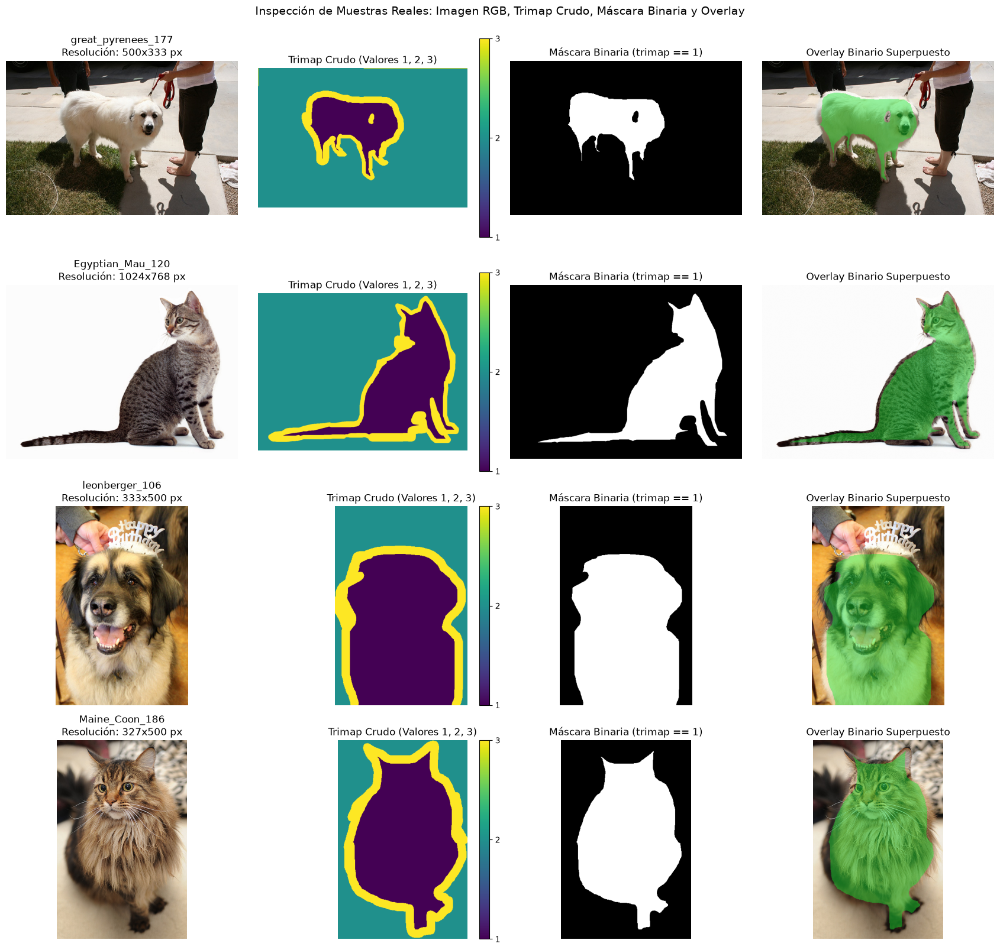

Porcentaje de píxeles por etiqueta en las muestras inspeccionadas (Resolución Original):


,1 = Mascota (Primer Plano),2 = Fondo,3 = Borde Ambiguo
great_pyrenees_177,11.4,80.8,7.7
Egyptian_Mau_120,22.1,66.5,11.5
leonberger_106,55.0,30.7,14.3
Maine_Coon_186,45.9,35.1,19.0


In [3]:
TRIMAP_NAMES = {1: "1 = Mascota (Primer Plano)", 2: "2 = Fondo", 3: "3 = Borde Ambiguo"}  # Diccionario de nombres

# Funcion que desnormaliza los tensores RGB a imagenes visualizables en [0, 1]
def denorm(img_t):
    img = img_t.permute(1, 2, 0).cpu().numpy()  # Permuta de [C, H, W] a [H, W, C]
    return np.clip(img * np.array(PetSegDataset.STD) + np.array(PetSegDataset.MEAN), 0, 1)  # Desnormaliza y recorta

# Funcion show_sample
def show_sample(ds, idx, axes_row):
    img, trimap = ds.load_raw(idx)  # Carga la imagen y el trimap crudos en resolucion original
    tri = np.array(trimap)  # Conviertel trimap a matriz NumPy
    binary = (tri == 1).astype(np.uint8)  # Genera la mascara binaria: 1 si es mascota, 0 en otro caso
    overlay = np.array(img).astype(float) / 255.0  # Normaliza la imagen PIL a rango [0, 1] para construir el overlay
    overlay[binary == 1] = 0.55 * overlay[binary == 1] + 0.45 * np.array([0.1, 0.9, 0.2])  # Resalta la mascota en verde brillante
    
    axes_row[0].imshow(img)  # Grafica la imagen RGB original
    axes_row[0].set_title(f"{ds.names[idx]}\nResolución: {img.size[0]}x{img.size[1]} px") 
    im = axes_row[1].imshow(tri, cmap="viridis", vmin=1, vmax=3) 
    axes_row[1].set_title("Trimap Crudo (Valores 1, 2, 3)")  
    plt.colorbar(im, ax=axes_row[1], ticks=[1, 2, 3], fraction=0.046)
    axes_row[2].imshow(binary, cmap="gray") 
    axes_row[2].set_title("Máscara Binaria (trimap == 1)")  
    axes_row[3].imshow(overlay) 
    axes_row[3].set_title("Overlay Binario Superpuesto")
    for ax in axes_row:  
        ax.axis("off")  
    vals, counts = np.unique(tri, return_counts=True) 
    return {TRIMAP_NAMES[v]: round(c / tri.size * 100, 1) for v, c in zip(vals, counts)} 

# Selecciona 4 muestras para ejecutar show_sample
sample_ids = [0, 7, 21, 42]
fig, axes = plt.subplots(len(sample_ids), 4, figsize=(17, 4 * len(sample_ids)))
stats = {}  
for row, idx in enumerate(sample_ids):  
    stats[train_ds.names[idx]] = show_sample(train_ds, idx, axes[row]) 
plt.suptitle("Inspección de Muestras Reales: Imagen RGB, Trimap Crudo, Máscara Binaria y Overlay", fontsize=14, y=1.0) 
plt.tight_layout() 
save_fig("act1_show_sample.png")  
plt.show()  

df_stats = pd.DataFrame(stats).T.fillna(0.0)  
print("Porcentaje de píxeles por etiqueta en las muestras inspeccionadas (Resolución Original):") 
display(df_stats)

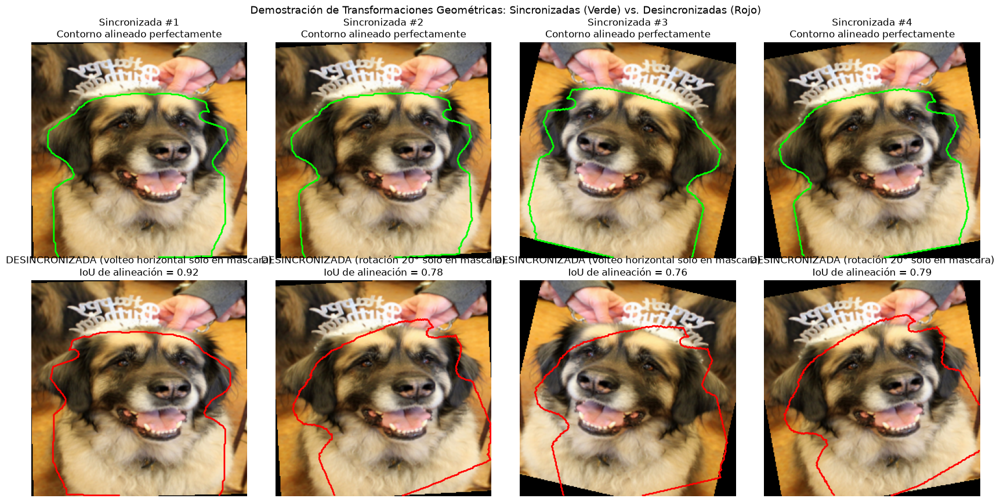

In [4]:
# Demostracion de transformaciones estocasticas Sincronizadas vs Desincronizadas
def iou_np(a, b):  # Funcion para calcular IoU escalar entre dos arreglos binarios NumPy
    a, b = a.astype(bool), b.astype(bool)
    return (a & b).sum() / max((a | b).sum(), 1)  # Interseccion sobre Union

set_seed(3)  # Fijar semilla

fig, axes = plt.subplots(2, 4, figsize=(17, 8.8))
for k in range(4): 
    img_t, mask_t = train_ds[21] 
    img = denorm(img_t)  # Denormalizar imagen RGB
    m = mask_t[0].numpy()  # Extraer mascara transformada

    axes[0, k].imshow(img)
    axes[0, k].contour(m, levels=[0.5], colors="lime", linewidths=2)  
    axes[0, k].set_title(f"Sincronizada #{k+1}\nContorno alineado perfectamente") 
    
    # Aplicar la transformacion espacial solo a la mascara
    bad = np.fliplr(m) if k % 2 == 0 else ndimage.rotate(m, 20, reshape=False, order=0)  # Desalinear mascara
    axes[1, k].imshow(img)  # Graficar la misma imagen RGB
    axes[1, k].contour(bad, levels=[0.5], colors="red", linewidths=2)  # Superponer contorno desalineado en ROJO
    kind = "volteo horizontal" if k % 2 == 0 else "rotación 20°"  # Tipo de desalineamiento
    axes[1, k].set_title(f"DESINCRONIZADA ({kind} solo en máscara)\nIoU de alineación = {iou_np(m, bad):.2f}")

for ax in axes.ravel():
    ax.axis("off")  
plt.suptitle("Demostración de Transformaciones Geométricas: Sincronizadas (Verde) vs. Desincronizadas (Rojo)", fontsize=13) 
plt.tight_layout() 
save_fig("act1_sync_transforms.png") 
plt.show()

Valores únicos del trimap con BILINEAR: [1, 2, 3]
Valores únicos del trimap con NEAREST : [1, 2, 3]

Píxeles corrompidos en la máscara binaria con BILINEAR:
 1.52% de los píxeles (valores entre 0.0 y 1.0)

Valores únicos en máscara binaria con NEAREST: [0.0, 1.0] (Estrictamente binario)


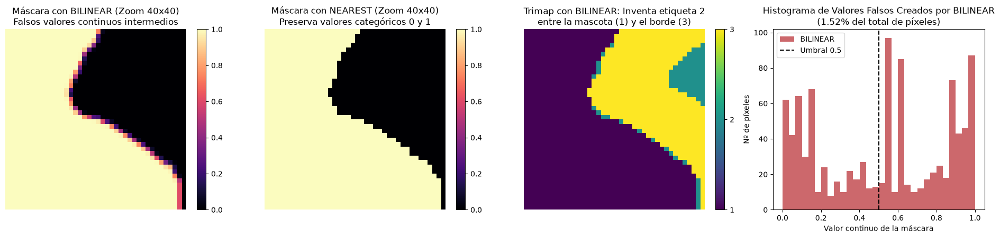

In [5]:
# Demostración cuantitativa y visual de NEAREST vs BILINEAR en Máscaras
img_raw, trimap_raw = train_ds.load_raw(21) 
tri_bil = np.array(trimap_raw.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))  # Resize trimap con BILINEAR (Incorrecto)
tri_nea = np.array(trimap_raw.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST))  # Resize trimap con NEAREST (Correcto)

bin_src = Image.fromarray((np.array(trimap_raw) == 1).astype(np.float32))  # Mascara binaria en float
bin_bil = np.array(bin_src.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))  # Resize binario con BILINEAR que roduce flotantes
bin_nea = np.array(bin_src.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST))  # Resize binario con NEAREST que mantiene 0 y 1

frac_px = ((bin_bil > 0) & (bin_bil < 1)).mean() * 100  # Calcula el porcentaje de pixeles corrompidos (no binarios)
fake_bg = ((tri_bil == 2) & (tri_nea != 2)).sum()  # Cuenta los pixeles etiquetados falsamente como fondo por BILINEAR

print(f"Valores únicos del trimap con BILINEAR: {np.unique(tri_bil).tolist()}") 
print(f"Valores únicos del trimap con NEAREST : {np.unique(tri_nea).tolist()}") 
print(f"\nPíxeles corrompidos en la máscara binaria con BILINEAR:\n {frac_px:.2f}% de los píxeles (valores entre 0.0 y 1.0)")  # Falsa continuidad
print(f"\nValores únicos en máscara binaria con NEAREST: {np.unique(bin_nea).tolist()} (Estrictamente binario)")  # Binario puro

# Extraer una region de zoom de 40x40 en el borde del objeto para evidenciar la corrupcion
edge = bin_nea.astype(bool) ^ ndimage.binary_erosion(bin_nea.astype(bool))  # Extraer borde
cy, cx = np.argwhere(edge)[len(np.argwhere(edge)) // 2]  # Seleccionar punto central del borde
win = (slice(cy - 20, cy + 20), slice(cx - 20, cx + 20))  # Definir ventana de zoom

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))  # Crear rejilla 1 x 4
im0 = axes[0].imshow(bin_bil[win], cmap="magma", vmin=0, vmax=1)  # Zoom BILINEAR
axes[0].set_title("Máscara con BILINEAR (Zoom 40x40)\nFalsos valores continuos intermedios")
plt.colorbar(im0, ax=axes[0], fraction=0.046) 
im1 = axes[1].imshow(bin_nea[win], cmap="magma", vmin=0, vmax=1)  # Zoom NEAREST
axes[1].set_title("Máscara con NEAREST (Zoom 40x40)\nPreserva valores categóricos 0 y 1") 
plt.colorbar(im1, ax=axes[1], fraction=0.046) 
im2 = axes[2].imshow(tri_bil[win], cmap="viridis", vmin=1, vmax=3)  # Zoom Trimap BILINEAR
axes[2].set_title("Trimap con BILINEAR: Inventa etiqueta 2\nentre la mascota (1) y el borde (3)") 
plt.colorbar(im2, ax=axes[2], ticks=[1, 2, 3], fraction=0.046) 
axes[3].hist(bin_bil[(bin_bil > 0) & (bin_bil < 1)], bins=30, color="#C44E52", alpha=0.85, label="BILINEAR")  # Histograma
axes[3].axvline(0.5, color="k", ls="--", label="Umbral 0.5")  # Umbral
axes[3].set_title(f"Histograma de Valores Falsos Creados por BILINEAR\n({frac_px:.2f}% del total de píxeles)")  # Titulo
axes[3].set_xlabel("Valor continuo de la máscara")  # Eje x
axes[3].set_ylabel("Nº de píxeles")  # Eje y
axes[3].legend() 
for ax in axes[:3]:  
    ax.axis("off") 
plt.tight_layout()  
save_fig("act1_nearest_vs_bilinear.png") 
plt.show() 

Fracción de primer plano (Mascota)
  - Media: 30.3% | Mín: 0.0% | Máx: 90.4%
Imágenes con menos del 15% de área de mascota (Desbalance severo): 18.7%


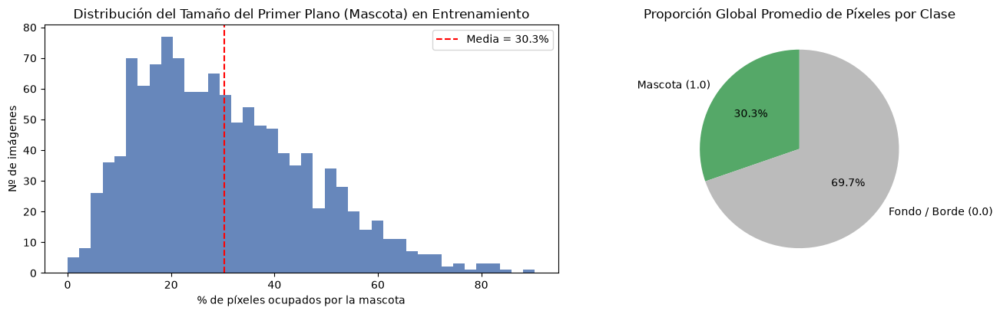

In [6]:
# Calcular y analizar la distribucion del primer plano (mascota) en el dataset de entrenamiento
fg_frac = np.array([(np.array(Image.open(TRIMAPS_DIR / f"{n}.png")) == 1).mean() for n in train_names]) 
RESULTS["dataset"] = {"n_train": len(train_names), "n_test": len(test_names), "fg_mean": float(fg_frac.mean()), "fg_min": float(fg_frac.min()), "fg_max": float(fg_frac.max()), "fg_lt_15pct": float((fg_frac < 0.15).mean())}

print(f"Fracción de primer plano (Mascota)\n  - Media: {fg_frac.mean() * 100:.1f}% | Mín: {fg_frac.min() * 100:.1f}% | Máx: {fg_frac.max() * 100:.1f}%") 
print(f"Imágenes con menos del 15% de área de mascota (Desbalance severo): {(fg_frac < 0.15).mean() * 100:.1f}%") 

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)) 
ax[0].hist(fg_frac * 100, bins=40, color="#4C72B0", alpha=0.85)  # Histograma de distribucion de primer plano
ax[0].axvline(fg_frac.mean() * 100, color="r", ls="--", label=f"Media = {fg_frac.mean() * 100:.1f}%")  # Linea de media
ax[0].set_xlabel("% de píxeles ocupados por la mascota") 
ax[0].set_ylabel("Nº de imágenes")  
ax[0].set_title("Distribución del Tamaño del Primer Plano (Mascota) en Entrenamiento")
ax[0].legend()  
ax[1].pie([fg_frac.mean(), 1 - fg_frac.mean()], labels=["Mascota (1.0)", "Fondo / Borde (0.0)"], autopct="%1.1f%%", colors=["#55A868", "#BBBBBB"], startangle=90)  
ax[1].set_title("Proporción Global Promedio de Píxeles por Clase") 
plt.tight_layout() 
save_fig("act1_desbalance.png")
plt.show()  

**Importancia de sincronizar las transformaciones:** 
- La imagen y su máscara describen la misma escena. Si se rota o refleja solo una de ellas, dejan de coincidir los píxeles con sus etiquetas y el modelo recibe ejemplos mal etiquetados.
- Por eso, las transformaciones geométricas deben aplicarse a ambas con los mismos parámetros. Las transformaciones de color, en cambio, se aplican solo a la imagen.

### **¿Por qué se usa interpolación `NEAREST` para la máscara y `BILINEAR` para la imagen al hacer resize?** 
> - **Imagen RGB (`BILINEAR`):** Las imágenes fotográficas contienen intensidades de color continuas ($[0, 255]$). La interpolación bilineal promedia suavemente los valores de los píxeles vecinos al cambiar la resolución, evitando bordes pixelados o artefactos escalonados.

> - **Máscara Trimap / Binaria (`NEAREST`):** La máscara contiene **etiquetas categóricas discretas** ($0, 1, 2, 3$). La interpolación por el vecino más cercano (`NEAREST`) asigna a cada nuevo píxel el valor numérico exacto de su vecino original más cercano sin realizar ningún cálculo de promedios.

### **¿Qué pasaría si usaras bilineal para ambas?**

> Si se aplicara interpolación bilineal a la máscara, al promediar los valores en los bordes de transición (por ejemplo entre el fondo $0$ y la mascota $1$), se inventarían **falsos valores fraccionarios intermedios continuos** (valores fraccionarios no enteros). Esto corrompería la definición categórica binaria de la máscara, introduciendo parches ambiguos que distorsionarían las funciones de pérdida y arruinarían el cálculo de métricas como el IoU.

## **Actividad 2 — Construir U-Net desde Cero (Modelo M1)**

```
Entrada [B, 3, 256, 256]
    │
DoubleConv(3 → 64) ────> (Skip 1: [B, 64, 256, 256]) ──> Concatenar con dec4 ─> Salida [B, 1, 256, 256]
    │ MaxPool 2x2
DoubleConv(64 → 128) ──> (Skip 2: [B, 128, 128, 128]) ─> Concatenar con dec3
    │ MaxPool 2x2
DoubleConv(128 → 256) ─> (Skip 3: [B, 256, 64, 64]) ───> Concatenar con dec2
    │ MaxPool 2x2
DoubleConv(256 → 512) ─> (Skip 4: [B, 512, 32, 32]) ───> Concatenar con dec1
    │ MaxPool 2x2
DoubleConv(512 → 1024) [BOTTLENECK: B, 1024, 16, 16]
```



In [7]:
# Bloque de convolucion doble DoubleConv (Conv3x3 -> BatchNorm -> ReLU) x 2
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):  # Constructor de DoubleConv
        super().__init__()  # Inicializa la clase padre nn.Module
        self.net = nn.Sequential(  # Crea la secuencia de capas
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),  # Primera convolucion 3x3 manteniendo H y W (padding=1)
            nn.BatchNorm2d(out_c),  # Normalizacion por lotes sobre out_c canales
            nn.ReLU(inplace=True),  # Funcion de activacion
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),  # Segunda convolucion 3x3
            nn.BatchNorm2d(out_c),  # Normalizacion por lotes
            nn.ReLU(inplace=True)  # Funcion de activacion 
        ) 

    def forward(self, x):  # Forward del bloque DoubleConv
        return self.net(x)  # Pasa el tensor x a traves del bloque secuencial net

# Bloque de reconstrucción del decoder UpBlock (Upsampling + Concatenacion Skip + DoubleConv)
class UpBlock(nn.Module):  
    def __init__(self, in_c, skip_c, out_c):  # Constructor de UpBlock
        super().__init__()  
        self.up = nn.ConvTranspose2d(in_c, in_c // 2, kernel_size=2, stride=2)  # Convolucion transpuesta para duplicar H y W
        self.conv = DoubleConv(in_c // 2 + skip_c, out_c)  # DoubleConv para procesar la concatenacion de canales

    def forward(self, x, skip):  # Forward recibiendo mapa inferior y mapa de skip connection
        x = self.up(x)  # Duplica resolucion espacial mediante convolucion transpuesta
        dh, dw = skip.shape[2] - x.shape[2], skip.shape[3] - x.shape[3]  # Calcula la posible diferencia de dimensiones
        x = F.pad(x, [dw // 2, dw - dw // 2, dh // 2, dh - dh // 2])  # Rellena con ceros si existe diferencia impar
        return self.conv(torch.cat([skip, x], dim=1))  # Concatena el mapa de skip y mapa subido por el eje de canales

# Clase de la arquitectura U-Net completa desde cero
class UNet(nn.Module): 
    def __init__(self, in_channels=3, num_classes=1, features=(64, 128, 256, 512)):  # Constructor de UNet
        super().__init__() 
        self.encoders = nn.ModuleList()  # Inicializa la lista de submódulos para el encoder
        c = in_channels  # Canales iniciales de entrada (3 para RGB)
        for f in features:  # Construye cada nivel del encoder
            self.encoders.append(DoubleConv(c, f))  # Agrega el bloque DoubleConv
            c = f  # Actualiza los canales de entrada para el siguiente nivel
        self.pool = nn.MaxPool2d(2)  # Reduccion espacial por max pooling 2x2
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)  # Cuello de bottella con doble convolucion y el doble de canales 
        self.decoders = nn.ModuleList()  # Inicializa la lista de submódulos para el decoder
        c = features[-1] * 2  # Canales iniciales salientes del bottleneck (1024)
        for f in reversed(features):  # Construye los niveles del decoder en orden inverso de canales
            self.decoders.append(UpBlock(c, f, f))  # Agrega el UpBlock que recibe la skip de f canales
            c = f  # Actualiza los canales de salida
        self.head = nn.Conv2d(features[0], num_classes, kernel_size=1)  # Proyeccion final 1x1 a num_classes logits

    # Forward de la u-net
    def forward(self, x):
        skips = []  # Inicializa la lista para guardar mapas de caracteristicas de skip connections
        for enc in self.encoders:  # Itera sobre los bloques del encoder
            x = enc(x)  # Procesa la entrada a traves de DoubleConv
            skips.append(x)  # Guarda el  # Imprimir mascara real mapa de alta resolucion para el decoder
            x = self.pool(x)  # Reduce la resolucion espacial a la mitad con MaxPool2d
        x = self.bottleneck(x)  # Procesa en el cuello de botella de maxima abstraccion semantica (16x16)
        for dec, skip in zip(self.decoders, reversed(skips)):  # Itera sobre decoders usando skipsde forma inversa
            x = dec(x, skip)  # Upsampling + Concatenacion con la skip correspondiente + DoubleConv
        return self.head(x)  # Proyecta a logits finales [B, num_classes, H, W]

# Prueba estricta de shapes
unet_test = UNet(in_channels=3, num_classes=1)  # Instancia el modelo UNet desde cero
x_test = torch.randn(2, 3, 256, 256)  # Crear tensor de entrada aleatorio con forma [2, 3, 256, 256]
with torch.no_grad():  # Desactivar calculo de gradientes para la prueba de formas tensoriales
    y_test = unet_test(x_test)  # Pase hacia adelante (forward pass)

print(f"Forma Tensor de Entrada UNet : {list(x_test.shape)}") 
print(f"Forma Tensor de Salida UNet  : {list(y_test.shape)}")
assert y_test.shape == (2, 1, 256, 256), "¡Error: La salida de la U-Net no coincide con [2, 1, 256, 256]!"  # Asertion

print(f"\nParámetros totales entrenables de la U-Net desde cero: {sum(p.numel() for p in unet_test.parameters()):,}")  # Conteo

Forma Tensor de Entrada UNet : [2, 3, 256, 256]
Forma Tensor de Salida UNet  : [2, 1, 256, 256]

Parámetros totales entrenables de la U-Net desde cero: 31,037,633


Flujo Tensorial Detallado de la U-Net por Bloque Arquitectónico:


,Bloque,Forma de Salida,Resolución Espacial,Canales
0,enc1 (Skip 1),"[2, 64, 256, 256]",256,64
1,enc2 (Skip 2),"[2, 128, 128, 128]",128,128
2,enc3 (Skip 3),"[2, 256, 64, 64]",64,256
3,enc4 (Skip 4),"[2, 512, 32, 32]",32,512
4,Bottleneck,"[2, 1024, 16, 16]",16,1024
5,dec1 (Usa Skip 4),"[2, 512, 32, 32]",32,512
6,dec2 (Usa Skip 3),"[2, 256, 64, 64]",64,256
7,dec3 (Usa Skip 2),"[2, 128, 128, 128]",128,128
8,dec4 (Usa Skip 1),"[2, 64, 256, 256]",256,64
9,Head 1x1,"[2, 1, 256, 256]",256,1


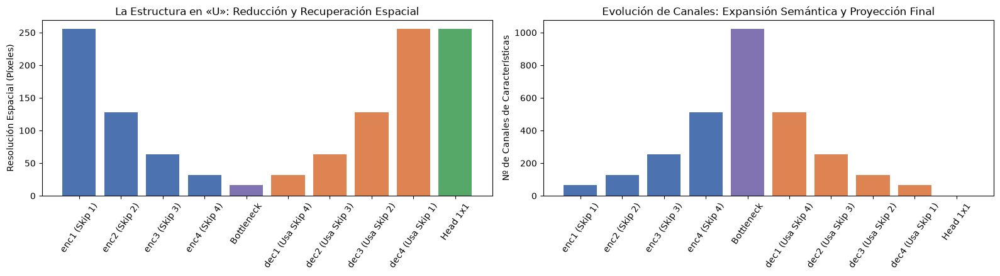

In [8]:
# Rastrear la reconstruccion de shapes paso a paso mediante Forward Hooks
records = []  # Lista para almacenar registros de dimensiones
def make_hook(name):  # Funcion creadora de hooks de inspeccion tensorial
    def hook(module, inp, out):  # Definicion del hook
        records.append({"Bloque": name, "Forma de Salida": str(list(out.shape)), "Resolución Espacial": out.shape[2], "Canales": out.shape[1]})  # Registra
    return hook  # Retorna el hook

handles = []  # Lista de manejadores de hooks
for i, m in enumerate(unet_test.encoders):  # Registrar hooks en el encoder
    handles.append(m.register_forward_hook(make_hook(f"enc{i+1} (Skip {i+1})")))  # Hook encoder
handles.append(unet_test.bottleneck.register_forward_hook(make_hook("Bottleneck")))  # Hook bottleneck

for i, m in enumerate(unet_test.decoders):  # Registra hooks en el decoder
    handles.append(m.register_forward_hook(make_hook(f"dec{i+1} (Usa Skip {4-i})")))  # Hook decoder
handles.append(unet_test.head.register_forward_hook(make_hook("Head 1x1")))  # Hook head

with torch.no_grad():  # Desactiva los gradientes
    unet_test(x_test)  # Dispara el forward
for h in handles:  # Limpia hooks
    h.remove() 

df_shapes = pd.DataFrame(records)  # DataFrame con el flujo de formas tensoriales
print("Flujo Tensorial Detallado de la U-Net por Bloque Arquitectónico:")  # Banner
display(df_shapes)  # Renderizar tabla


bar_colors = ["#4C72B0"] * 4 + ["#8172B2"] + ["#DD8452"] * 4 + ["#55A868"] 
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5)) 
ax[0].bar(df_shapes["Bloque"], df_shapes["Resolución Espacial"], color=bar_colors)
ax[0].set_ylabel("Resolución Espacial (Píxeles)")
ax[0].set_title("La Estructura en «U»: Reducción y Recuperación Espacial")
ax[0].tick_params(axis="x", rotation=55)
ax[1].bar(df_shapes["Bloque"], df_shapes["Canales"], color=bar_colors)
ax[1].set_ylabel("Nº de Canales de Características")
ax[1].set_title("Evolución de Canales: Expansión Semántica y Proyección Final")
ax[1].tick_params(axis="x", rotation=55)

plt.tight_layout()  
save_fig("act2_shapes_unet.png")  
plt.show() 

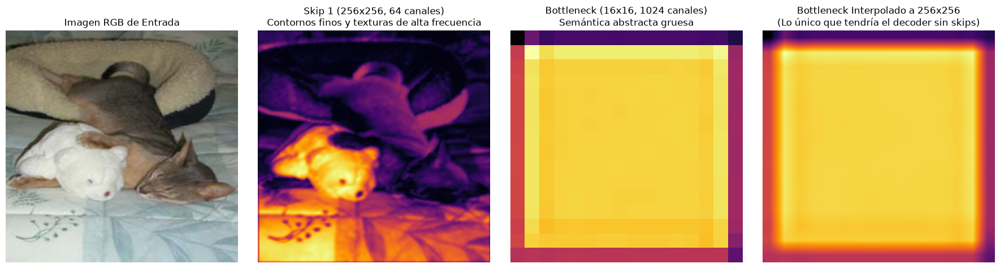

In [ ]:
# Demostracion visual del aporte de las Skip Connections vs. Bottleneck aislado
feats = {}
h1 = unet_test.encoders[0].register_forward_hook(lambda m, i, o: feats.__setitem__("skip1", o)) 
h2 = unet_test.bottleneck.register_forward_hook(lambda m, i, o: feats.__setitem__("bottleneck", o))

img_t, mask_t = test_ds[5]  # Carga una muestra real del conjunto de prueba
unet_test.eval()  # Configura el modelo en modo evaluacion

with torch.no_grad():  # Desactiva los gradientes
    unet_test(img_t.unsqueeze(0))  # Forward pass
h1.remove(); h2.remove() 

s1 = feats["skip1"][0].abs().mean(0).numpy()  # Promedio de activacion de la Skip 1 (256x256)
bt = feats["bottleneck"][0].abs().mean(0, keepdim=True)  # Promedio de activacion del Bottleneck (16x16)
bt_up = F.interpolate(bt.unsqueeze(0), size=(256, 256), mode="bilinear", align_corners=False)[0, 0].numpy()  # Interpolacion bilineal pura del bottleneck

fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
ax[0].imshow(denorm(img_t)) 
ax[0].set_title("Imagen RGB de Entrada") 
ax[1].imshow(s1, cmap="inferno")  # Activacion Skip 1
ax[1].set_title("Skip 1 (256x256, 64 canales)\nContornos finos y texturas de alta frecuencia")
ax[2].imshow(feats["bottleneck"][0].abs().mean(0).numpy(), cmap="inferno") 
ax[2].set_title("Bottleneck (16x16, 1024 canales)\nSemántica abstracta gruesa") 
ax[3].imshow(bt_up, cmap="inferno")  # Bottleneck sin skips
ax[3].set_title("Bottleneck Interpolado a 256x256\n(Lo único que tendría el decoder sin skips)")
\
for a in ax:
    a.axis("off")  
plt.tight_layout() 

save_fig("act2_skip_vs_bottleneck.png")  
plt.show() 

del unet_test  # Liberar modelo de prueba de la memoria GPU

**Recorrido en forma de «U»:** La tabla y las gráficas muestran cómo cambian las dimensiones de la red:
  - **Encoder:** Comprime progresivamente la resolución espacial ($256\rightarrow 128\rightarrow 64\rightarrow 32\rightarrow 16$) duplicando los canales ($64\rightarrow 128\rightarrow 256\rightarrow 512\rightarrow 1024$).
   
  - **Decoder:** Duplica la resolución espacial en cada paso ($16\rightarrow 32\rightarrow 64\rightarrow 128\rightarrow 256$) mediante convolución transpuesta, concatenando la *skip connection* del nivel correspondiente y reduciendo los canales.

**Qué aportan las skip connections:** 
 - Los mapas de las capas iniciales conservan información espacial que se reduce al hacer *downsampling*. Al concatenarlos con las capas del decoder, este puede usar tanto esas señales de mayor resolución como la información semántica del *bottleneck*. La visualización ilustra esta diferencia en las activaciones, aunque no mide por sí sola el efecto sobre el resultado final.

### **¿Qué información aportan las skip connections que el decoder no podría recuperar por sí solo?**
> Aportan **información espacial fina y detalles de alta resolución** (como la posición exacta de bordes, texturas de pelaje y contornos nítidos) que se pierden durante las operaciones de *downsampling* (pooling y convoluciones con stride) en el encoder. Mientras el encoder sacrifica resolución espacial para abstraer la semántica de alto nivel ("qué objeto hay"), el decoder por sí solo solo podría generar máscaras borrosas e imprecisas. Las *skip connections* transfieren los mapas de características no comprimidos del encoder al decoder, permitiendo que la red combine la semántica global del bottleneck con la localización espacial fina de las capas iniciales.

## **Actividad 3 — Funciones de Pérdida para Segmentación**

In [10]:
# Definir la funcion de perdida DiceLoss basada en el solapamiento suave de regiones
class DiceLoss(nn.Module): 
    def __init__(self, smooth=1.0):  # Constructor con constante de suavizado
        super().__init__()  # Inicializar nn.Module
        self.smooth = smooth  # Guardar valor de suavizado para evitar division entre cero

    def forward(self, logits, targets):  # Metodo forward recibiendo logits no binarizados y mascaras objetivo
        probs = torch.sigmoid(logits)  # Convierte logits continuos a probabilidades en el rango (0, 1) mediante sigmoid
        dims = (1, 2, 3)  # Define dimensiones espaciales y de canal para sumar por imagen en el lote
        intersection = (probs * targets).sum(dims)  # Calcula interseccion suave diferenciable |P ∩ T|
        cardinality = probs.sum(dims) + targets.sum(dims)  # Suma cardinalidades suaves |P| + |T|
        dice = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)  # Coeficiente Dice suave por muestra
        return 1.0 - dice.mean()  # Retorna la perdida (1.0 - Dice) promediada sobre el lote

# Definir la funcion de perdida combinada BCEDiceLoss
class BCEDiceLoss(nn.Module):
    def __init__(self):  # Constructor de la perdida compuesta
        super().__init__()  # Inicializa nn.Module
        self.bce = nn.BCEWithLogitsLoss()  # Instancia Binary Cross-Entropy con logits numéricamente estable
        self.dice = DiceLoss()  # Instancia DiceLoss orientada a regiones

    def forward(self, logits, targets):  # Metodo forward recibiendo logits y objetivos
        return self.bce(logits, targets) + self.dice(logits, targets)  # Retorna la suma escalar de ambas perdidas

# Definir la funcion reutilizable para calcular las metricas de evaluacion IoU y Dice Score
def compute_metrics(logits, targets, threshold=0.5): 
    preds = (torch.sigmoid(logits) > threshold).float()  # Aplica sigmoid y umbraliza a valores binarios 0.0 o 1.0
    intersection = (preds * targets).sum().item()  # Suma verdaderos positivos |P ∩ T|
    total_preds = preds.sum().item()  # Suma el total de pixeles predichos como positivos |P|
    total_targets = targets.sum().item()  # Suma el total de pixeles reales positivos |T|
    union = total_preds + total_targets - intersection  # Calcula la union de regiones |P ∪ T|
    iou = (intersection + 1e-6) / (union + 1e-6)  # Calcula Intersection over Union (IoU)
    dice = (2.0 * intersection + 1e-6) / (total_preds + total_targets + 1e-6)  # Calcula Coeficiente Dice
    return iou, dice  # Devuelve la tupla de valores escalares flotantes (IoU, Dice)

# Demostración detallada con tensores pequeños de 4x4
t44 = torch.tensor([[0, 0, 0, 0], [0, 1, 1, 0], [0, 1, 1, 0], [0, 0, 0, 0]], dtype=torch.float32).view(1, 1, 4, 4)  # Mascara real: Objeto de 4 pixeles en el centro
l44 = torch.tensor([[-3, -3, -3, -3], [-3, 2, 2, -3], [-3, 2, -1, 1], [-3, -3, -3, -3]], dtype=torch.float32).view(1, 1, 4, 4).requires_grad_()  # Logits con 1 FN y 1 FP

p44 = torch.sigmoid(l44)  # Probabilidades
b44 = (p44 > 0.5).float()  # Prediccion binaria
tp, fp, fn = (b44 * t44).sum().item(), (b44 * (1 - t44)).sum().item(), ((1 - b44) * t44).sum().item()  # Matriz de confusion

bce_val = nn.BCEWithLogitsLoss()(l44, t44)  # Evalua BCE
dice_val = DiceLoss()(l44, t44)  # Evalua DiceLoss
comb_val = BCEDiceLoss()(l44, t44)  # Evalua BCEDiceLoss
comb_val.backward()  # Ejecuta retropropagacion de gradientes para verificar diferenciabilidad

iou_val, dice_metric = compute_metrics(l44.detach(), t44)  # Calcula metricas duras

print("Muestra de Prueba 4x4 (Máscara Real T):\n", t44[0, 0].int().numpy())
print(f"\nProbabilidades `sigmoid(logits)` (P):\n", p44[0, 0].detach().numpy().round(2))  
print(f"\nPredicción Binaria (`P > 0.5`):\n", b44[0, 0].int().numpy())  
print(f"\nMatriz de Confusión\n  -> TP: {tp:.0f} | FP: {fp:.0f} | FN: {fn:.0f}")
print(f"\nMétricas Duras\n  - IoU = TP/(TP+FP+FN) = {iou_val:.4f} | Dice = 2TP/(2TP+FP+FN) = {dice_metric:.4f}")  # Metricas
print(f"\nPérdidas Escalares\n  - BCEWithLogits = {bce_val.item():.4f} | DiceLoss = {dice_val.item():.4f} | BCEDiceLoss = {comb_val.item():.4f}")  # Perdidas
print(f"\nVerificación de Gradientes Válidos (dL/dLogits): {torch.isfinite(l44.grad).all().item()}")  # Gradientes

Muestra de Prueba 4x4 (Máscara Real T):
 [[0 0 0 0]
 [0 1 1 0]
 [0 1 1 0]
 [0 0 0 0]]

Probabilidades `sigmoid(logits)` (P):
 [[0.05 0.05 0.05 0.05]
 [0.05 0.88 0.88 0.05]
 [0.05 0.88 0.27 0.73]
 [0.05 0.05 0.05 0.05]]

Predicción Binaria (`P > 0.5`):
 [[0 0 0 0]
 [0 1 1 0]
 [0 1 0 1]
 [0 0 0 0]]

Matriz de Confusión
  -> TP: 3 | FP: 1 | FN: 1

Métricas Duras
  - IoU = TP/(TP+FP+FN) = 0.6000 | Dice = 2TP/(2TP+FP+FN) = 0.7500

Pérdidas Escalares
  - BCEWithLogits = 0.2214 | DiceLoss = 0.2555 | BCEDiceLoss = 0.4769

Verificación de Gradientes Válidos (dL/dLogits): True


Comportamiento del Modelo TRIVIAL ('Predice Siempre Fondo') ante Desbalance de Clases:


,% Objeto Real,Accuracy (Píxel),IoU Metric,Dice Metric,BCE Loss,DiceLoss
0,0.5,0.9951,0.0,0.0,0.0379,0.9916
1,1.0,0.9897,0.0,0.0,0.0594,0.9864
2,2.0,0.9802,0.0,0.0,0.0973,0.9808
3,5.0,0.9504,0.0,0.0,0.2165,0.9734
4,10.0,0.8999,0.0,0.0,0.4186,0.9694
5,20.0,0.8017,0.0,0.0,0.8114,0.9670
6,30.0,0.7009,0.0,0.0,1.2144,0.9660
7,50.0,0.5001,0.0,0.0,2.0177,0.9652


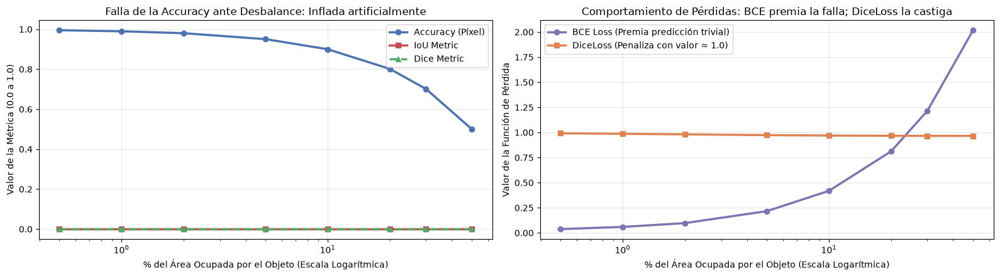

In [11]:
# Experimento cuantitativo del modelo TRIVIAL "Todo Fondo" ante distintos niveles de desbalance de clases
fracs = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5])  # Diferentes porcentajes de ocupacion del objeto (0.5% a 50%)
rows = [] 

for f in fracs:  # Iterar sobre cada proporcion de desbalance
    side = int(round(np.sqrt(f) * IMG_SIZE))  # Lado del cuadrado representativo
    tgt = torch.zeros(1, 1, IMG_SIZE, IMG_SIZE)  # Crea la mascara objetivo de ceros (Fondo)
    s0 = (IMG_SIZE - side) // 2  # Posicion inicial para centrar el objeto
    tgt[..., s0:s0 + side, s0:s0 + side] = 1.0  # Dibuja el objeto real
    
    trivial_logits = torch.full_like(tgt, -4.0)  # Modelo trivial que predice fondo con confianza (sigmoid(-4) = 0.018)
    pred_bin = (torch.sigmoid(trivial_logits) > 0.5).float()  # Prediccion binaria (Todo Ceros)
    
    acc = (pred_bin == tgt).float().mean().item()  # Calcula el Accuracy por pixel
    iou_t, dice_t = compute_metrics(trivial_logits, tgt)  # Calcula IoU y Dice
    bce_loss_val = nn.BCEWithLogitsLoss()(trivial_logits, tgt).item()  # Calcula BCE Loss
    dice_loss_val = DiceLoss()(trivial_logits, tgt).item()  # Calcula Dice Loss
    
    rows.append({"% Objeto Real": f * 100, "Accuracy (Píxel)": acc, "IoU Metric": iou_t, "Dice Metric": dice_t, "BCE Loss": bce_loss_val, "DiceLoss": dice_loss_val}) 

df_imb = pd.DataFrame(rows)
print("Comportamiento del Modelo TRIVIAL ('Predice Siempre Fondo') ante Desbalance de Clases:")  # Banner
display(df_imb.round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))  
ax[0].plot(df_imb["% Objeto Real"], df_imb["Accuracy (Píxel)"], "o-", color="#4C72B0", lw=2.5, label="Accuracy (Píxel)")  # Accuracy
ax[0].plot(df_imb["% Objeto Real"], df_imb["IoU Metric"], "s-", color="#C44E52", lw=2.5, label="IoU Metric")  # IoU
ax[0].plot(df_imb["% Objeto Real"], df_imb["Dice Metric"], "^--", color="#55A868", lw=2.5, label="Dice Metric")  # Dice
ax[0].set_xscale("log")  # Escala logaritmica en X
ax[0].set_xlabel("% del Área Ocupada por el Objeto (Escala Logarítmica)")
ax[0].set_ylabel("Valor de la Métrica (0.0 a 1.0)")
ax[0].set_title("Falla de la Accuracy ante Desbalance: Inflada artificialmente")
ax[0].legend()  
ax[0].grid(alpha=0.3) 

ax[1].plot(df_imb["% Objeto Real"], df_imb["BCE Loss"], "o-", color="#8172B2", lw=2.5, label="BCE Loss (Premia predicción trivial)")  # BCE
ax[1].plot(df_imb["% Objeto Real"], df_imb["DiceLoss"], "s-", color="#DD8452", lw=2.5, label="DiceLoss (Penaliza con valor ≈ 1.0)")  # DiceLoss
ax[1].set_xscale("log")  # Escala logaritmica
ax[1].set_xlabel("% del Área Ocupada por el Objeto (Escala Logarítmica)")
ax[1].set_ylabel("Valor de la Función de Pérdida")
ax[1].set_title("Comportamiento de Pérdidas: BCE premia la falla; DiceLoss la castiga")
ax[1].legend() 
ax[1].grid(alpha=0.3) 

plt.tight_layout() 
save_fig("act3_desbalance_perdidas.png") 
plt.show() 

**Comprobación de la pérdida:** 
> La prueba con datos sintéticos verifica que el cálculo de la pérdida produce un valor finito y que se pueden obtener gradientes. Es una comprobación básica de la implementación, no una medida del rendimiento del modelo con imágenes reales.

**Comportamiento de Pérdidas ante Desbalance de Clases:**
> En el ejemplo sintético, el fondo ocupa la mayor parte de la imagen. Por eso, un predictor que clasifica todo como fondo puede lograr un accuracy alto y aun así no detectar la mascota. Dice responde al solapamiento de las regiones y no cuenta los verdaderos negativos de la misma forma que el accuracy. El ejemplo ayuda a entender la diferencia entre métricas, pero no demuestra que una pérdida sea siempre indispensable.

### **Por qué CrossEntropyLoss falla ante desbalance de clases?**
> - **Fallo de CrossEntropy / BCE:** `CrossEntropyLoss` evalúa cada píxel de forma **independiente**, promediando el error píxel a píxel sobre toda la imagen. Si el 90% de los píxeles pertenecen al fondo, un modelo trivial que prediga **siempre fondo** obtendrá un 90% de exactitud y una pérdida BCE muy baja, ignorando por completo el objeto de interés. La clase mayoritaria sobrecarga los gradientes del entrenamiento.

### **¿Qué mide exactamente el coeficiente Dice?**

> - Mide el **solapamiento relativo de volumen/área** entre la región predicha $P$ y la región real $T$:
>   $$\text{Dice} = \frac{2 |P \cap T|}{|P| + |T|}$$
>   A diferencia de BCE, los Verdaderos Negativos (píxeles de fondo correctamente predichos como fondo) **no intervienen en el numerador ni en el denominador** de la fórmula de Dice. Por lo tanto, el coeficiente Dice no se deja inflar por un fondo grande y mide estrictamente la calidad de la reconstrucción del objeto de interés.

## **Actividad 4 — Entrenar U-Net como Línea Base (Modelo M1)**

In [ ]:
# Definir funcion para asegurar que las capas BatchNorm congeladas permanezcan en eval() durante train()
def keep_frozen_bn_in_eval(model):
    for m in model.modules():  # Itera sobre todos los submodulos de la red
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):  # Si es BatchNorm congelada
            m.eval()  # Fuerza modo eval para no alterar medias y varianzas running

# Definir funcion para evaluar un modelo sobre un conjunto de datos completo acumulando la matriz de confusion
def evaluate(model, loader, criterion=None, threshold=0.5):
    model.eval()  # Modelo en modo evaluacion
    tp = fp = fn = tn = 0.0  # Acumuladores de la matriz de confusion global
    loss_sum, n = 0.0, 0  # Acumuladores de perdida escalar
    with torch.no_grad():  # Desactiva el calculo de gradientes
        for x, y in loader:  # Itera sobre los lotes del dataloader
            x, y = x.to(device), y.to(device)  # Transfiere imagenes y mascaras a GPU
            with torch.autocast(device.type, enabled=USE_AMP):  # Precision mixta
                logits = model(x)  # Forward passNL
            logits = logits.float()  # Asegura float32 para calculos estables
            if criterion is not None:  # Si se proporciona funcion de perdida
                loss_sum += criterion(logits, y).item() * x.size(0)  # Acumula la perdida ponderada
            n += x.size(0)  # Acumula el conteo de muestras
            p = (torch.sigmoid(logits) > threshold).float()  # Binariza las predicciones con el umbral
            tp += (p * y).sum().item()  # Verdaderos Positivos globales
            fp += (p * (1.0 - y)).sum().item()  # Falsos Positivos globales
            fn += ((1.0 - p) * y).sum().item()  # Falsos Negativos globales
            tn += ((1.0 - p) * (1.0 - y)).sum().item()  # Verdaderos Negativos globales
    return {
        "loss": loss_sum / n if criterion is not None else float("nan"),  # Perdida promediada
        "iou": tp / (tp + fp + fn + 1e-6),  # IoU global acumulado
        "dice": 2.0 * tp / (2.0 * tp + fp + fn + 1e-6),  # Dice Score global acumulado
        "acc": (tp + tn) / (tp + tn + fp + fn + 1e-6),  # Accuracy global por pixel
        "precision": tp / (tp + fp + 1e-6),  # Precision global
        "recall": tp / (tp + fn + 1e-6)  # Recall global
    }

# Definir funcion auxiliar para crear un escritor de TensorBoard limpio por experimento
def new_writer(name): 
    run_dir = RUNS_DIR / name  # Ruta a la carpeta de registros
    shutil.rmtree(run_dir, ignore_errors=True)  # Limpia los eventos previos si existian
    return SummaryWriter(log_dir=str(run_dir))  # Retorna el objeto SummaryWriter

# Definir la funcion principal de entrenamiento genérico train_seg
def train_seg(model, train_loader, test_loader, criterion, optimizer, epochs, name, writer=None, epoch_offset=0):  # Definición de función
    hist = {k: [] for k in ["train_loss", "train_iou", "train_dice", "test_loss", "test_iou", "test_dice", "time"]}  # Historial
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)  # Escalador AMP
    
    for ep in range(1, epochs + 1):  # Itera por cada epoca de entrenamiento
        model.train()  # Configura el modelo en modo entrenamiento
        keep_frozen_bn_in_eval(model)  # Respeta el congelamiento de BatchNorm si aplica
        t0 = time.time()  # Mide el tiempo inicial
        tl = ti = td = 0.0  # Acumuladores del lote
        nb = 0  # Cuenta lotes
        
        for x, y in train_loader:  # Itera sobre lotes de entrenamiento
            x, y = x.to(device), y.to(device) 
            optimizer.zero_grad(set_to_none=True)  # Limpia los gradientes
            with torch.autocast(device.type, enabled=USE_AMP):  # Contexto AMP
                logits = model(x)  # Forward pass
            loss = criterion(logits.float(), y)  # Calcula la perdida
            scaler.scale(loss).backward()  # Retropropagacion escalada
            scaler.step(optimizer)  # Actualizacion de parametros
            scaler.update()  # Actualiza la escala AMP
            
            i, d = compute_metrics(logits.detach().float(), y)  # Calcula metricas del lote
            tl, ti, td, nb = tl + loss.item(), ti + i, td + d, nb + 1  # Acumular
            
        ev = evaluate(model, test_loader, criterion)  # Evalua el modelo al final de cada epoca en test set
        elapsed = time.time() - t0  # Tiempo transcurrido
        vals = {"train_loss": tl / nb, "train_iou": ti / nb, "train_dice": td / nb, "test_loss": ev["loss"], "test_iou": ev["iou"], "test_dice": ev["dice"], "time": elapsed}  # Valores
        
        for k, v in vals.items():  # Guarda en el historial
            hist[k].append(v)  # Agrega el valor
            
        if writer is not None:  # Registrar curvas en TensorBoard 
            step = epoch_offset + ep  # Paso global continuo
            for metric in ["loss", "iou", "dice"]:  # Registra las 3 metricas requeridas
                writer.add_scalars(metric, {"train": vals[f"train_{metric}"], "test": vals[f"test_{metric}"]}, step)  # Registra train/test
                writer.add_scalar(f"{metric}/test", vals[f"test_{metric}"], step)  # Registra test individual
            writer.flush()  # Escriben en disco
            
        print(f"[{name}] Época {ep}/{epochs} | Train Loss: {vals['train_loss']:.4f} IoU: {vals['train_iou']:.4f} Dice: {vals['train_dice']:.4f} | Test Loss: {vals['test_loss']:.4f} IoU: {vals['test_iou']:.4f} Dice: {vals['test_dice']:.4f} | Tiempo: {elapsed:.1f}s") 
        
    if device.type == "cuda":  # Libera la memoria de GPU
        torch.cuda.empty_cache()  # Vacia la cache de VRAM
    return hist  # Devuelve el historial completo

# Definir funcion para generar matriz RGB de codigo de colores de error
def error_rgb(pred, gt):  # Definición de función con argumentos de entrada
    rgb = np.zeros((*gt.shape, 3))  # Negro = Verdadero Negativo (Fondo bien clasificado)
    rgb[(pred == 1) & (gt == 1)] = [0.2, 0.8, 0.2]  # VERDE: Verdadero Positivo (Mascota bien detectada)
    rgb[(pred == 1) & (gt == 0)] = [0.95, 0.1, 0.1]  # ROJO: Falso Positivo (Fondo clasificado erróneamente como mascota)
    rgb[(pred == 0) & (gt == 1)] = [0.1, 0.35, 1.0]  # AZUL: Falso Negativo (Mascota omitida)
    return rgb  # Devuelve mapa RGB

# Definir la funcion de visualización comparativa visualize_predictions exigida en la Actividad 7
def visualize_predictions(models_dict, dataset, indices, threshold=0.5, title="", fname=None):
    cols = 2 + len(models_dict)  # Numero de columnas (Imagen RGB, Ground Truth, y 1 columna por modelo)
    fig, axes = plt.subplots(len(indices), cols, figsize=(3.7 * cols, 3.7 * len(indices)))  # Rejilla
    axes = np.atleast_2d(axes)  # Asegurar matriz 2D
    
    for r, idx in enumerate(indices):  # Itera sobre las muestras seleccionadas
        x, y = dataset[idx]  # Carga la imagen y mascara
        gt = y[0].numpy().astype(int)  # Extrae Ground Truth
        axes[r, 0].imshow(denorm(x)) 
        axes[r, 0].set_title(f"Imagen #{idx}")
        axes[r, 1].imshow(gt, cmap="gray") 
        axes[r, 1].set_title("Ground Truth (Real)")
        
        for c, (mname, model) in enumerate(models_dict.items()):  # Itera sobre cada modelo a evaluar
            model.eval()  # Modo evaluacion
            with torch.no_grad(), torch.autocast(device.type, enabled=USE_AMP):  # Precision mixta
                prob = torch.sigmoid(model(x.unsqueeze(0).to(device)).float())[0, 0].cpu().numpy()  # Probabilidades
            pred = (prob > threshold).astype(int)  # Binarizar prediccion con umbral
            axes[r, 2 + c].imshow(error_rgb(pred, gt))
            axes[r, 2 + c].contour(gt, levels=[0.5], colors="white", linewidths=0.8)  # Superponer contorno real en blanco
            axes[r, 2 + c].set_title(f"{mname}\nIoU = {iou_np(pred, gt):.3f}")
            
    for ax in axes.ravel():  
        ax.axis("off") 
        
    legend_elements = [  
        Patch(color=(0.2, 0.8, 0.2), label="Verde: Verdadero Positivo (TP)"),
        Patch(color=(0.95, 0.1, 0.1), label="Rojo: Falso Positivo (FP)"), 
        Patch(color=(0.1, 0.35, 1.0), label="Azul: Falso Negativo (FN)"), 
        Patch(color="k", label="Negro: Verdadero Negativo (TN)") 
    ]  # Elementos de leyenda
    fig.legend(handles=legend_elements, loc="lower center", ncol=4, fontsize=11, bbox_to_anchor=(0.5, -0.01)) 
    plt.suptitle(title, fontsize=14)  
    plt.tight_layout(rect=(0, 0.03, 1, 1))  
    if fname:  
        save_fig(fname) 
    plt.show() 

# Definir funcion para contar parametros totales y entrenables de un modelo
def count_params(model):  
    total = sum(p.numel() for p in model.parameters())  # Sumar parametros totales
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)  # Sumar parametros entrenables
    return total, trainable  # Devuelve tupla (total, entrenables)

print("Infraestructura de entrenamiento (train_seg, evaluate, visualize_predictions) lista.")  # Banner

Infraestructura de entrenamiento (train_seg, evaluate, visualize_predictions) lista.


In [13]:
# Instanciar y entrenar el Modelo M1 (UNet Baseline desde cero)
set_seed(42)
m1 = UNet(in_channels=3, num_classes=1).to(device)  # Instancia UNet y mover a GPU
criterion = BCEDiceLoss()  # Instancia la funcion de perdida combinada BCEDiceLoss
opt_m1 = optim.Adam(m1.parameters(), lr=1e-3)  # Optimizador Adam con lr=1e-3
writer_m1 = new_writer("M1_UNet_scratch")  # Crear escritor de TensorBoard para M1

t_start = time.time()  # Registrar tiempo inicial
hist_m1 = train_seg(m1, train_loader, test_loader, criterion, opt_m1, EPOCHS, "M1_UNet_Baseline", writer_m1)  # Entrenar 5 epocas
time_m1 = time.time() - t_start  # Tiempo total
writer_m1.close()  # Cerrar escritor de TensorBoard

torch.save(m1.state_dict(), MODEL_DIR / "m1_unet_scratch.pth")  # Guardar checkpoint de M1 en disco
tot_m1, trn_m1 = count_params(m1)  # Obtener conteo de parametros
RESULTS["M1"] = {"hist": hist_m1, "time": time_m1, "params_total": tot_m1, "params_trainable": trn_m1}  # Registrar resultados
save_results()  # Persistir resultados en disco

print(f"\n[M1 Entrenamiento Finalizado] -> Tiempo: {time_m1:.1f}s | Parámetros Entrenables: {trn_m1:,}")
print(f"[M1 Evaluación Final Test Set] -> IoU: {hist_m1['test_iou'][-1]:.4f} | Dice Score: {hist_m1['test_dice'][-1]:.4f}") 

[M1_UNet_Baseline] Época 1/5 | Train Loss: 1.0689 IoU: 0.4110 Dice: 0.5766 | Test Loss: 0.9803 IoU: 0.4860 Dice: 0.6541 | Tiempo: 129.5s
[M1_UNet_Baseline] Época 2/5 | Train Loss: 0.9048 IoU: 0.4850 Dice: 0.6515 | Test Loss: 1.0426 IoU: 0.5055 Dice: 0.6716 | Tiempo: 105.0s
[M1_UNet_Baseline] Época 3/5 | Train Loss: 0.8902 IoU: 0.4871 Dice: 0.6537 | Test Loss: 0.8818 IoU: 0.4999 Dice: 0.6666 | Tiempo: 105.4s
[M1_UNet_Baseline] Época 4/5 | Train Loss: 0.8745 IoU: 0.4896 Dice: 0.6560 | Test Loss: 1.0908 IoU: 0.3574 Dice: 0.5266 | Tiempo: 108.2s
[M1_UNet_Baseline] Época 5/5 | Train Loss: 0.8816 IoU: 0.4872 Dice: 0.6534 | Test Loss: 0.8465 IoU: 0.5086 Dice: 0.6742 | Tiempo: 110.5s

[M1 Entrenamiento Finalizado] -> Tiempo: 558.7s | Parámetros Entrenables: 31,037,633
[M1 Evaluación Final Test Set] -> IoU: 0.5086 | Dice Score: 0.6742


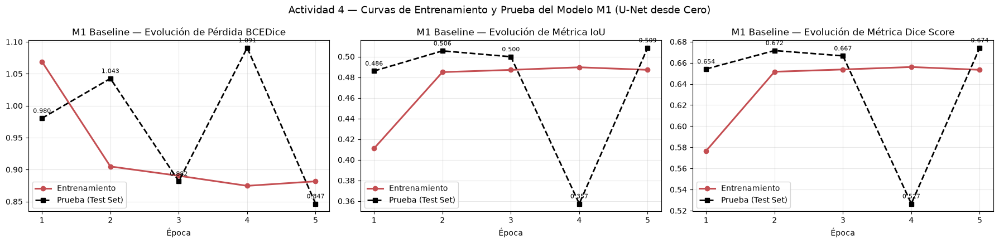

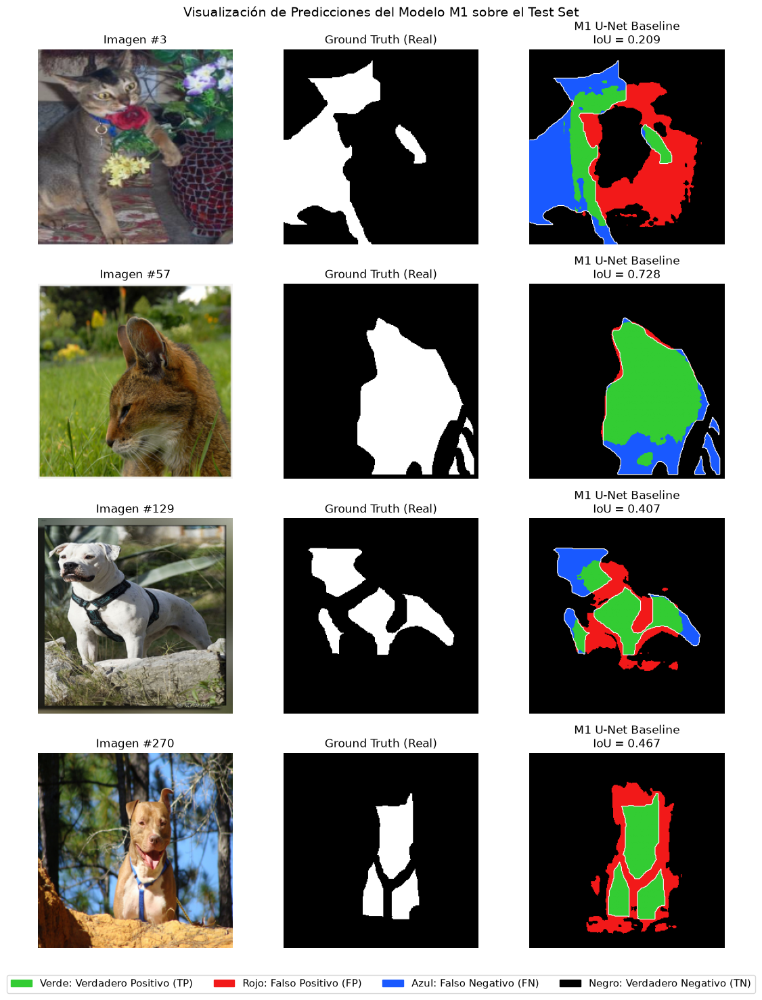

In [14]:
# Graficar las 3 curvas de entrenamiento y prueba para M1 (Loss, IoU, Dice)
ep = np.arange(1, EPOCHS + 1)  # Eje de epocas de 1 a 5
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))

for a, metric, label in zip(ax, ["loss", "iou", "dice"], ["Pérdida BCEDice", "Métrica IoU", "Métrica Dice Score"]):  # Iterar
    a.plot(ep, hist_m1[f"train_{metric}"], "o-", color=COLORS["M1"], lw=2.2, label="Entrenamiento")  # Curva train
    a.plot(ep, hist_m1[f"test_{metric}"], "s--", color="k", lw=2.0, label="Prueba (Test Set)")  # Curva test
    for e, v in zip(ep, hist_m1[f"test_{metric}"]):  # Anotar valores numéricos en cada punto de test
        a.annotate(f"{v:.3f}", (e, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)  # Anotacion
    a.set_xlabel("Época") 
    a.set_title(f"M1 Baseline — Evolución de {label}") 
    a.set_xticks(ep)  # Marcas enteras en las epocas
    a.grid(alpha=0.3)
    a.legend()

plt.suptitle("Actividad 4 — Curvas de Entrenamiento y Prueba del Modelo M1 (U-Net desde Cero)", fontsize=13) 
plt.tight_layout()  
save_fig("act4_curvas_m1.png") 
plt.show()  

# Predicciones del Modelo M1 en muestras seleccionadas del conjunto de prueba
VIS_IDX = [3, 57, 129, 270]  # Índices fijos del test set para mantener comparabilidad entre modelos
visualize_predictions({"M1 U-Net Baseline": m1}, test_ds, VIS_IDX, title="Visualización de Predicciones del Modelo M1 sobre el Test Set", fname="act4_pred_m1.png") 

**Evolución del entrenamiento (M1):** 
> En las salidas guardadas de las cinco épocas, la pérdida de entrenamiento bajó en términos generales, pero las métricas del test fluctuaron. El IoU final registrado fue 0.5086 y el Dice 0.6742; por eso, no describiría la mejora como continua. Estas métricas son de la ejecución anterior y no del test oficial completo.

**Limitación de la Inicialización Aleatoria:** 
> La corrida de cinco épocas no permite saber cuánto mejoraría la U-Net con más entrenamiento. Sus resultados sirven como línea base para compararla con los modelos que usan un encoder preentrenado.

**Predicciones de M1:** 
> En las muestras visualizadas aparecen falsos negativos cerca de algunas patas, la cola y el pelaje, y falsos positivos en partes del fondo. Esto sugiere dónde falla M1 en esos ejemplos; la comparación de métricas con M2 y M3 ofrece evidencia más amplia sobre el efecto del encoder preentrenado.

## **Actividad 5 — ResNetUNet: Encoder Preentrenado como Backbone (Modelo M2)**

In [ ]:
# Definir la clase ResNetUNet reutilizando ResNet-18 preentrenado en ImageNet como backbone
class ResNetUNet(nn.Module): 
    def __init__(self, num_classes=1, pretrained=True):  # Constructor especificando clases y pesos
        super().__init__()  # Inicializar la clase padre nn.Module
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)  # Cargar ResNet-18
        
        # Construir los 5 niveles del encoder aprovechando los bloques de ResNet-18
        self.enc0 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)  # s0: [B, 64, 128, 128]
        self.enc1 = nn.Sequential(resnet.maxpool, resnet.layer1)        # s1: [B, 64, 64, 64]
        self.enc2 = resnet.layer2                                       # s2: [B, 128, 32, 32]
        self.enc3 = resnet.layer3                                       # s3: [B, 256, 16, 16]
        self.enc4 = resnet.layer4                                       # s4: [B, 512, 8, 8] (Bottleneck)
        
        # Construir el decoder ajustando los canales de entrada a la concatenacion de skip connections
        self.dec4 = DoubleConv(512 + 256, 256)  # Fusionar up(s4) [512] + s3 [256] = 768 canales -> 256 en 16x16
        self.dec3 = DoubleConv(256 + 128, 128)  # Fusionar up(d4) [256] + s2 [128] = 384 canales -> 128 en 32x32
        self.dec2 = DoubleConv(128 + 64, 64)    # Fusionar up(d3) [128] + s1 [64] = 192 canales -> 64 en 64x64
        self.dec1 = DoubleConv(64 + 64, 64)      # Fusionar up(d2) [64] + s0 [64] = 128 canales -> 64 en 128x128
        self.dec0 = DoubleConv(64, 32)          # Refinamiento final de up(d1) [64] -> 32 canales en 256x256
        
        self.head = nn.Conv2d(32, num_classes, kernel_size=1)  # Convolucion 1x1 final para proyectar a num_classes logits

    @staticmethod  # Metodo estatico para upsampling bilineal 2x
    def up(x):  
        return F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)  # Duplicar H y W

    # Metodo forward completado de RESNETUNet
    def forward(self, x): 
        s0 = self.enc0(x)  # Extraer nivel 0: 128x128, 64 canales
        s1 = self.enc1(s0)  # Extraer nivel 1: 64x64, 64 canales
        s2 = self.enc2(s1)  # Extraer nivel 2: 32x32, 128 canales
        s3 = self.enc3(s2)  # Extraer nivel 3: 16x16, 256 canales
        s4 = self.enc4(s3)  # Extraer nivel 4 (Bottleneck): 8x8, 512 canales
        
        d4 = self.dec4(torch.cat([self.up(s4), s3], dim=1))  # Decoder 4: 16x16, 256 canales
        d3 = self.dec3(torch.cat([self.up(d4), s2], dim=1))  # Decoder 3: 32x32, 128 canales
        d2 = self.dec2(torch.cat([self.up(d3), s1], dim=1))  # Decoder 2: 64x64, 64 canales
        d1 = self.dec1(torch.cat([self.up(d2), s0], dim=1))  # Decoder 1: 128x128, 64 canales
        d0 = self.dec0(self.up(d1))                          # Decoder 0: 256x256, 32 canales
        
        return self.head(d0)  # logits [B, 1, 256, 256]

# Instanciar e inspeccionar formas tensoriales de ResNetUNet
rnu_test = ResNetUNet()  # Modelo de prueba
records = []  # Lista de registros
handles = [getattr(rnu_test, n).register_forward_hook(make_hook(n)) for n in ["enc0", "enc1", "enc2", "enc3", "enc4", "dec4", "dec3", "dec2", "dec1", "dec0", "head"]]  # Hooks
with torch.no_grad():  # Sin gradientes
    out_rnu = rnu_test(torch.randn(2, 3, 256, 256))  # Forward pass
for h in handles:  # Limpiar hooks
    h.remove() 

df_rnu_shapes = pd.DataFrame(records)  # DataFrame de formas tensoriales
print("Flujo Tensorial de ResNetUNet por Bloque Arquitectónico:")  # Banner
display(df_rnu_shapes) 
assert out_rnu.shape == (2, 1, 256, 256), "¡Error: La salida de ResNetUNet no coincide con [2, 1, 256, 256]!"  # Assertion

del rnu_test  # Liberar modelo de prueba

Flujo Tensorial de ResNetUNet por Bloque Arquitectónico:


,Bloque,Forma de Salida,Resolución Espacial,Canales
0,enc0,"[2, 64, 128, 128]",128,64
1,enc1,"[2, 64, 64, 64]",64,64
2,enc2,"[2, 128, 32, 32]",32,128
3,enc3,"[2, 256, 16, 16]",16,256
4,enc4,"[2, 512, 8, 8]",8,512
5,dec4,"[2, 256, 16, 16]",16,256
6,dec3,"[2, 128, 32, 32]",32,128
7,dec2,"[2, 64, 64, 64]",64,64
8,dec1,"[2, 64, 128, 128]",128,64
9,dec0,"[2, 32, 256, 256]",256,32


Resumen de Parámetros
  - Total: 14,413,537 | Entrenables: 3,237,025 (22.5%) | Congelados: 11,176,512 (77.5%)


,Bloque Arquitectónico,Parámetros Totales,Parámetros Entrenables,Estado del Bloque
0,enc0,9536,0,Congelado (Frozen)
1,enc1,147968,0,Congelado (Frozen)
2,enc2,525568,0,Congelado (Frozen)
3,enc3,2099712,0,Congelado (Frozen)
4,enc4,8393728,0,Congelado (Frozen)
5,dec4,2360320,2360320,Entrenable (Trainable)
6,dec3,590336,590336,Entrenable (Trainable)
7,dec2,147712,147712,Entrenable (Trainable)
8,dec1,110848,110848,Entrenable (Trainable)
9,dec0,27776,27776,Entrenable (Trainable)


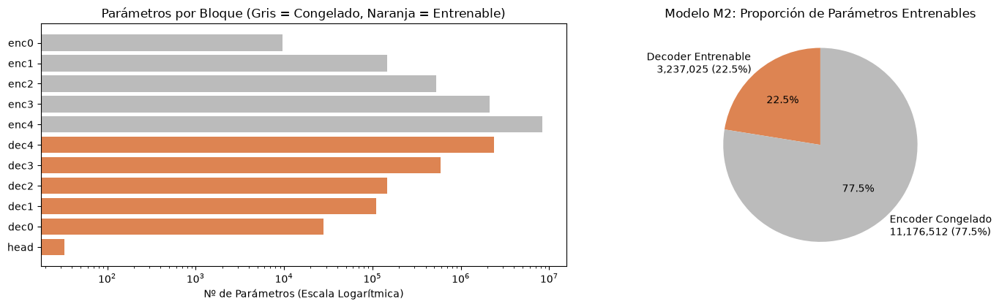

In [ ]:
# Definir funcion para congelar o descongelar las capas del encoder enc0..enc4
def freeze_encoder(model, freeze=True): 
    for name in ["enc0", "enc1", "enc2", "enc3", "enc4"]:  # Iterar sobre los submódulos del encoder
        for p in getattr(model, name).parameters():  # Iterar sobre cada parametro
            p.requires_grad = not freeze  # Fijar requires_grad = False para congelar, True para entrenar

# Definir funcion summary para inspeccionar y reportar la distribucion de parametros entrenables vs congelados
def summary(model): 
    rows = []  # Filas de la tabla
    for name, mod in model.named_children():  # Iterar sobre submódulos principales
        tot = sum(p.numel() for p in mod.parameters())  # Sumar parametros totales
        trn = sum(p.numel() for p in mod.parameters() if p.requires_grad)  # Sumar entrenables
        status = "Congelado (Frozen)" if tot > 0 and trn == 0 else "Entrenable (Trainable)"  # Estado
        rows.append({"Bloque Arquitectónico": name, "Parámetros Totales": tot, "Parámetros Entrenables": trn, "Estado del Bloque": status})  # Agregar
    df = pd.DataFrame(rows)  # Crear DataFrame
    total, trainable = df["Parámetros Totales"].sum(), df["Parámetros Entrenables"].sum()  # Totales
    frozen = total - trainable  # Congelados
    print(f"Resumen de Parámetros\n  - Total: {total:,} | Entrenables: {trainable:,} ({trainable/total*100:.1f}%) | Congelados: {frozen:,} ({frozen/total*100:.1f}%)") 
    return df  

# Instanciar el Modelo M2 (ResNetUNet) y congelar el encoder
set_seed(42)  
m2 = ResNetUNet().to(device)  # Instanciar ResNetUNet en GPU
freeze_encoder(m2, True)  
df_sum = summary(m2)  # Generar y mostrar summary de parametros
display(df_sum)  # Renderizar tabla

# Graficar la distribucion visual de parametros congelados vs entrenables
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3)) 
ax[0].barh(df_sum["Bloque Arquitectónico"], df_sum["Parámetros Totales"], color=["#BBBBBB" if s == "Congelado (Frozen)" else COLORS["M2"] for s in df_sum["Estado del Bloque"]])  # Horiz
ax[0].set_xscale("log") 
ax[0].invert_yaxis()  
ax[0].set_xlabel("Nº de Parámetros (Escala Logarítmica)") 
ax[0].set_title("Parámetros por Bloque (Gris = Congelado, Naranja = Entrenable)")

tot_m2, trn_m2 = count_params(m2)  # Obtener totales
ax[1].pie([trn_m2, tot_m2 - trn_m2], labels=[f"Decoder Entrenable\n{trn_m2:,} (22.5%)", f"Encoder Congelado\n{tot_m2 - trn_m2:,} (77.5%)"], autopct="%1.1f%%", colors=[COLORS["M2"], "#BBBBBB"], startangle=90)  # Pie
ax[1].set_title("Modelo M2: Proporción de Parámetros Entrenables")  

plt.tight_layout() 
save_fig("act5_summary_m2.png") 
plt.show()

In [17]:
# Entrenar el Modelo M2 (ResNetUNet Frozen) durante 5 epocas con Adam lr=1e-3
opt_m2 = optim.Adam([p for p in m2.parameters() if p.requires_grad], lr=1e-3)  # Optimizador Adam sobre parametros entrenables
writer_tl = new_writer("M2_M3_transfer")  # Escritor de TensorBoard compartido para M2 (Epocas 1-5) y M3 (Epocas 6-10)

t_start = time.time()  
hist_m2 = train_seg(m2, train_loader, test_loader, criterion, opt_m2, EPOCHS, "M2_ResNetUNet_Frozen", writer_tl, epoch_offset=0)  # Entrenar 5 epocas
time_m2 = time.time() - t_start  

torch.save(m2.state_dict(), MODEL_DIR / "m2_resnetunet_frozen.pth")  # Guardar checkpoint de M2
RESULTS["M2"] = {"hist": hist_m2, "time": time_m2, "params_total": tot_m2, "params_trainable": trn_m2}  # Registrar resultados
save_results() 

print(f"\n[M2 Entrenamiento Finalizado]\n  - Tiempo: {time_m2:.1f}s | Parámetros Entrenables: {trn_m2:,}")  # Banner
print(f"\n[M2 Evaluación Final Test Set]\n  - IoU: {hist_m2['test_iou'][-1]:.4f} | Dice Score: {hist_m2['test_dice'][-1]:.4f}")  # Banner
print(f"\nCheckpoint M2 Guardado Exitosamente en: outputs_parte_b/models/m2_resnetunet_frozen.pth")  # Rutas

[M2_ResNetUNet_Frozen] Época 1/5 | Train Loss: 0.6022 IoU: 0.7188 Dice: 0.8321 | Test Loss: 0.4129 IoU: 0.8045 Dice: 0.8917 | Tiempo: 58.3s
[M2_ResNetUNet_Frozen] Época 2/5 | Train Loss: 0.3496 IoU: 0.8073 Dice: 0.8927 | Test Loss: 0.2987 IoU: 0.8365 Dice: 0.9110 | Tiempo: 42.9s
[M2_ResNetUNet_Frozen] Época 3/5 | Train Loss: 0.2971 IoU: 0.8262 Dice: 0.9043 | Test Loss: 0.2687 IoU: 0.8415 Dice: 0.9139 | Tiempo: 43.2s
[M2_ResNetUNet_Frozen] Época 4/5 | Train Loss: 0.2798 IoU: 0.8330 Dice: 0.9084 | Test Loss: 0.2573 IoU: 0.8479 Dice: 0.9177 | Tiempo: 44.0s
[M2_ResNetUNet_Frozen] Época 5/5 | Train Loss: 0.2511 IoU: 0.8488 Dice: 0.9177 | Test Loss: 0.2656 IoU: 0.8426 Dice: 0.9146 | Tiempo: 44.8s

[M2 Entrenamiento Finalizado]
  - Tiempo: 233.2s | Parámetros Entrenables: 3,237,025

[M2 Evaluación Final Test Set]
  - IoU: 0.8426 | Dice Score: 0.9146

Checkpoint M2 Guardado Exitosamente en: outputs_parte_b/models/m2_resnetunet_frozen.pth


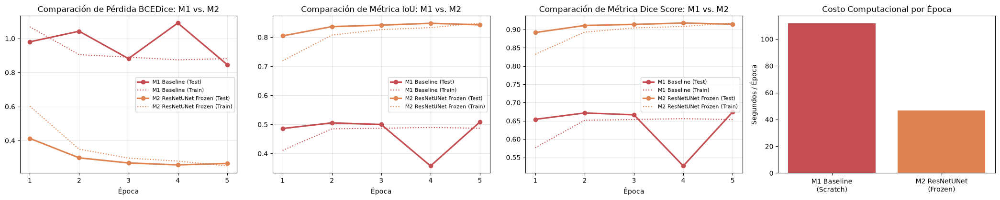

In [18]:
# Graficar la comparacion directa de curvas de entrenamiento M1 vs M2
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))

for a, metric, label in zip(ax[:3], ["loss", "iou", "dice"], ["Pérdida BCEDice", "Métrica IoU", "Métrica Dice Score"]):
    for key, h in [("M1 Baseline", hist_m1), ("M2 ResNetUNet Frozen", hist_m2)]:  # Recorrer historial
        col = COLORS["M1"] if "M1" in key else COLORS["M2"]
        a.plot(ep, h[f"test_{metric}"], "o-", color=col, lw=2.3, label=f"{key} (Test)")
        a.plot(ep, h[f"train_{metric}"], ":", color=col, lw=1.5, label=f"{key} (Train)")
    a.set_xlabel("Época")
    a.set_title(f"Comparación de {label}: M1 vs. M2")
    a.set_xticks(ep)
    a.grid(alpha=0.3)
    a.legend(fontsize=8) 

ax[3].bar(["M1 Baseline\n(Scratch)", "M2 ResNetUNet\n(Frozen)"], [np.mean(hist_m1["time"]), np.mean(hist_m2["time"])], color=[COLORS["M1"], COLORS["M2"]])  # Barras
ax[3].set_ylabel("Segundos / Época")
ax[3].set_title("Costo Computacional por Época")
plt.tight_layout()
save_fig("act5_m1_vs_m2.png")
plt.show()

**Reducción de Parámetros Entrenables:** 
> Con el encoder congelado, el optimizador actualiza el decoder, pero no los pesos de ResNet-18. Esto reduce el número de parámetros que se entrenan en comparación con M1, aunque no significa que el costo computacional sea proporcionalmente menor: el encoder todavía debe procesar cada imagen.

**Resultado de esta corrida:**
> En las salidas anteriores, M2 registró IoU 0.8426 y Dice 0.9146, frente a 0.5086 y 0.6742 de M1. La diferencia favorece a M2 en esa comparación. M2 tuvo 3.24 millones de parámetros entrenables, frente a 31.04 millones en M1. Para atribuir la diferencia solo al preentrenamiento habría que controlar el resto de las condiciones; además, los resultados se deben recalcular con el test oficial completo.

### **¿En qué se diferencia congelar el encoder aquí respecto a lo que hiciste con VGG en el workshop anterior?**

> - **En VGG (Clasificación de Imágenes):** 
>
>     Se congelaba el extractor convolucional de características y se entrenaba únicamente una pequeña cabeza clasificadora fully-connected (densa) en 1D. El mapa 2D se colapsaba a un vector mediante pooling global, perdiendo toda la información espacial.

> - **En ResNetUNet (Segmentación Semántica):** 
>
>   Al congelar el encoder ResNet-18, no solo se reutiliza la salida profunda ($s4$), sino que se extrae los mapas intermedios a 5 resoluciones espaciales distintas ($s0, s1, s2, s3, s4$). Además, la parte entrenable no es un clasificador simple de unas cuantas neuronas, sino un **decoder convolucional completo en 2D**. Este decoder debe aprender a fusionar la información de ImageNet con las *skip connections* para reconstruir una imagen completa de etiquetas píxel a píxel. Así, es importante mantener las capas `BatchNorm2d` del encoder en modo `eval()` para prevenir que se actualicen sus estadísticas running.

## **Actividad 6 — Fine-Tuning End-to-End (Modelo M3)**

In [19]:
# Instanciar el Modelo M3 (ResNetUNet Fine-Tuned) y cargar el checkpoint guardado de M2
m3 = ResNetUNet().to(device) 
m3.load_state_dict(torch.load(MODEL_DIR / "m2_resnetunet_frozen.pth", map_location=device))  # Cargar pesos de M2
freeze_encoder(m3, False)  # Descongelar el encoder

print("Verificación de Parámetros de M3 tras el Descongelamiento Completo:")  # Banner
_ = summary(m3)  # Renderizar summary confirmando 100% de parametros entrenables

# Guardar una copia exacta de los tensores de pesos del encoder antes del fine-tuning para medir cambios
enc_before = {n: {k: v.detach().clone() for k, v in getattr(m3, n).state_dict().items()} for n in ["enc0", "enc1", "enc2", "enc3", "enc4"]}  # Clonar

# Configurar el optimizador Adam sobre el 100% de los parametros con lr = 1e-4 estricto del PDF
set_seed(42)  
opt_m3 = optim.Adam(m3.parameters(), lr=1e-4)  # Optimizador Adam con lr=1e-4

t_start = time.time()
# Entrenar por 5 epocas adicionales (epoch_offset=5 hace que en TensorBoard se registre en los pasos 6 a 10)
hist_m3 = train_seg(m3, train_loader, test_loader, criterion, opt_m3, EPOCHS, "M3_ResNetUNet_FineTuned", writer_tl, epoch_offset=EPOCHS)  # Train
time_m3 = time.time() - t_start 
writer_tl.close()  # Cerrar el escritor de TensorBoard compartido

torch.save(m3.state_dict(), MODEL_DIR / "m3_resnetunet_finetuned.pth")  # Guardar checkpoint M3
tot_m3, trn_m3 = count_params(m3)  # Totales
RESULTS["M3"] = {"hist": hist_m3, "time": time_m3, "params_total": tot_m3, "params_trainable": trn_m3}  # Registrar resultados
save_results()  # Persistir resultados

print(f"\n[M3 Entrenamiento Finalizado]\n  - Tiempo: {time_m3:.1f}s | Parámetros Entrenables: {trn_m3:,} (100%)")  # Banner
print(f"\n[M3 Evaluación Final Test Set]\n  - IoU: {hist_m3['test_iou'][-1]:.4f} | Dice Score: {hist_m3['test_dice'][-1]:.4f}")  # Banner

Verificación de Parámetros de M3 tras el Descongelamiento Completo:
Resumen de Parámetros
  - Total: 14,413,537 | Entrenables: 14,413,537 (100.0%) | Congelados: 0 (0.0%)
[M3_ResNetUNet_FineTuned] Época 1/5 | Train Loss: 0.2677 IoU: 0.8377 Dice: 0.9111 | Test Loss: 0.2520 IoU: 0.8510 Dice: 0.9195 | Tiempo: 51.2s
[M3_ResNetUNet_FineTuned] Época 2/5 | Train Loss: 0.2277 IoU: 0.8609 Dice: 0.9248 | Test Loss: 0.2331 IoU: 0.8617 Dice: 0.9257 | Tiempo: 47.1s
[M3_ResNetUNet_FineTuned] Época 3/5 | Train Loss: 0.2100 IoU: 0.8715 Dice: 0.9310 | Test Loss: 0.2340 IoU: 0.8614 Dice: 0.9256 | Tiempo: 48.4s
[M3_ResNetUNet_FineTuned] Época 4/5 | Train Loss: 0.1991 IoU: 0.8788 Dice: 0.9353 | Test Loss: 0.2308 IoU: 0.8644 Dice: 0.9273 | Tiempo: 47.2s
[M3_ResNetUNet_FineTuned] Época 5/5 | Train Loss: 0.1940 IoU: 0.8798 Dice: 0.9358 | Test Loss: 0.2354 IoU: 0.8619 Dice: 0.9258 | Tiempo: 47.9s

[M3 Entrenamiento Finalizado]
  - Tiempo: 241.8s | Parámetros Entrenables: 14,413,537 (100%)

[M3 Evaluación Final

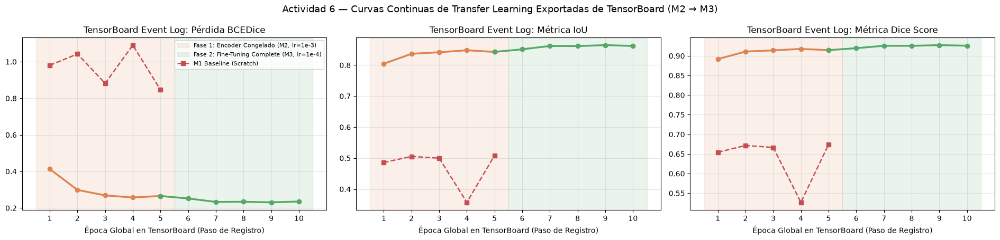

In [20]:
# Funcion para extraer curvas escalares grabadas en los archivos de eventos de TensorBoard
def read_tb(run_name, tag):
    ea = EventAccumulator(str(RUNS_DIR / run_name))  # Instanciar acumulador
    ea.Reload()  # Cargar eventos
    ev = ea.Scalars(tag)  # Extraer la lista de eventos escalares de la etiqueta dada
    return [e.step for e in ev], [e.value for e in ev]  # Retornar tupla (pasos, valores)

# Leer y graficar las curvas continuas exportadas de TensorBoard para las dos fases (M2 y M3)
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6)) 

for a, metric, label in zip(ax, ["loss", "iou", "dice"], ["Pérdida BCEDice", "Métrica IoU", "Métrica Dice Score"]):  # Iterar
    s_m2m3, v_m2m3 = read_tb("M2_M3_transfer", f"{metric}/test")  # Leer secuencia continua M2->M3 de TensorBoard
    s_m1, v_m1 = read_tb("M1_UNet_scratch", f"{metric}/test")  # Leer secuencia M1
    
    a.axvspan(0.5, EPOCHS + 0.5, color=COLORS["M2"], alpha=0.12, label="Fase 1: Encoder Congelado (M2, lr=1e-3)")  # Sombrear M2
    a.axvspan(EPOCHS + 0.5, 2 * EPOCHS + 0.5, color=COLORS["M3"], alpha=0.12, label="Fase 2: Fine-Tuning Complete (M3, lr=1e-4)")  # Sombrear M3
    
    a.plot(s_m2m3[:EPOCHS], v_m2m3[:EPOCHS], "o-", color=COLORS["M2"], lw=2.5)  # Tramo M2 (Pasos 1-5)
    a.plot(s_m2m3[EPOCHS - 1:], v_m2m3[EPOCHS - 1:], "o-", color=COLORS["M3"], lw=2.5)  # Tramo M3 (Pasos 5-10 continuos)
    a.plot(s_m1, v_m1, "s--", color=COLORS["M1"], lw=1.8, label="M1 Baseline (Scratch)")  # M1 referencia
    
    a.set_xlabel("Época Global en TensorBoard (Paso de Registro)")
    a.set_title(f"TensorBoard Event Log: {label}") 
    a.set_xticks(range(1, 2 * EPOCHS + 1))  # Marcas 1 a 10
    a.grid(alpha=0.3) 

ax[0].legend(fontsize=8) 
plt.suptitle("Actividad 6 — Curvas Continuas de Transfer Learning Exportadas de TensorBoard (M2 → M3)", fontsize=13)
plt.tight_layout()
save_fig("act6_tensorboard_m2_m3.png")
plt.show()

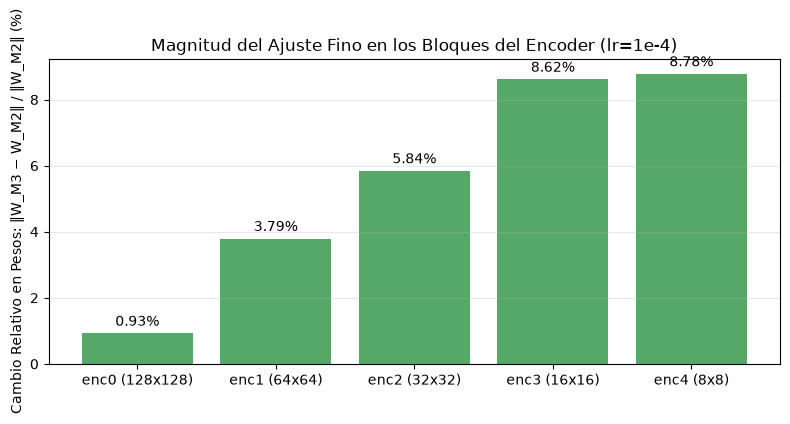

In [21]:
# Cuantificar la magnitud de actualizacion de pesos en cada bloque del encoder tras el fine-tuning con lr=1e-4
changes = []  # Lista para almacenar el porcentaje de cambio por bloque
for n in ["enc0", "enc1", "enc2", "enc3", "enc4"]:  # Iterar sobre bloques del encoder
    after = getattr(m3, n).state_dict()  # Pesos M3
    before = enc_before[n]  # Pesos M2
    num = sum(((after[k].float() - before[k].float().to(device)) ** 2).sum() for k in after if after[k].is_floating_point() and "running" not in k)  # ||W_M3 - W_M2||^2
    den = sum((before[k].float() ** 2).sum() for k in after if after[k].is_floating_point() and "running" not in k)  # ||W_M2||^2
    change_pct = float(torch.sqrt(num).cpu() / torch.sqrt(den)) * 100.0  # Porcentaje relativo
    changes.append(change_pct)  # Guardar

RESULTS.setdefault("M3", {})

RESULTS["M3"]["enc_change_pct"] = dict(
    zip(["enc0", "enc1", "enc2", "enc3", "enc4"], changes)
)
save_results()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(["enc0 (128x128)", "enc1 (64x64)", "enc2 (32x32)", "enc3 (16x16)", "enc4 (8x8)"], changes, color=COLORS["M3"])  # Barras
ax.bar_label(bars, fmt="%.2f%%", padding=3) 
ax.set_ylabel("Cambio Relativo en Pesos: ‖W_M3 − W_M2‖ / ‖W_M2‖ (%)")
ax.set_title("Magnitud del Ajuste Fino en los Bloques del Encoder (lr=1e-4)")  
ax.grid(axis="y", alpha=0.3) 
plt.tight_layout()  
save_fig("act6_cambio_pesos_encoder.png") 
plt.show()  

**Resultado del fine-tuning (M3):** 
> En las salidas anteriores, M3 registró IoU 0.8619 y Dice 0.9258, algo por encima de M2 (0.8426 y 0.9146). La diferencia es moderada en esa corrida de cinco épocas; habría que repetir el experimento antes de afirmar que descongelar el encoder mejora siempre el resultado. Estos números aún no corresponden a la evaluación actual sobre el test completo.

**Adaptación Gradual de Pesos:**
> Las normas de gradiente y los cambios de pesos muestran cómo se actualizó el encoder en esta corrida. Son compatibles con una adaptación durante el fine-tuning, pero no bastan para concluir qué detectores aprendió cada capa ni qué características conservaron.

## **Actividad 7 — Evaluación Comparativa y Visualización**

Tabla Comparativa De Resultados En El Test Set Completo con 400 Imágenes Reales


,Descripción,Test IoU,Test Dice Score,Accuracy (Píxel),Precisión,Recall,Parámetros Entrenables,Tiempo Total (s)
Modelo,,,,,,,,
M1,U-Net construida desde cero,0.5086,0.6742,0.8013,0.6632,0.6856,"31,037,633",558.700000
M2,ResNet-18 encoder congelado,0.8426,0.9146,0.9494,0.9261,0.9033,"3,237,025",233.200000
M3,ResNet-18 fine-tuning end-to-end,0.8619,0.9258,0.9554,0.9234,0.9283,"14,413,537",241.800000


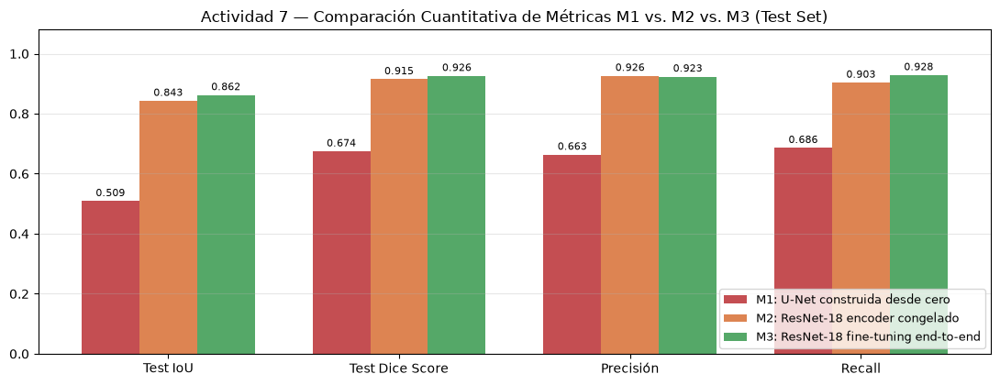

In [22]:
# Evaluar los 3 modelos sobre el conjunto de prueba completo de imágenes del test set
MODELS = {"M1 Baseline (Scratch)": m1, "M2 ResNetUNet (Frozen)": m2, "M3 ResNetUNet (Fine-Tuned)": m3}  # Modelos
DESC = {"M1 Baseline (Scratch)": "U-Net construida desde cero", "M2 ResNetUNet (Frozen)": "ResNet-18 encoder congelado", "M3 ResNetUNet (Fine-Tuned)": "ResNet-18 fine-tuning end-to-end"}  # Descripciones

missing_training_data = {
    key: sorted({"params_trainable", "time"} - RESULTS.get(key, {}).keys())
    for key in ("M1", "M2", "M3")
    if not {"params_trainable", "time"}.issubset(RESULTS.get(key, {}))
}
if missing_training_data:
    raise RuntimeError(
        "Faltan metadatos de entrenamiento para la comparación M1/M2/M3: "
        f"{missing_training_data}. Ejecuta las celdas de entrenamiento correspondientes "
        "o restaura los CSV de métricas antes de continuar."
    )

rows = []  # Filas de la tabla
for k, model in MODELS.items(): 
    ev = evaluate(model, test_loader, criterion)  
    key_short = k.split()[0]  # Obtener clave corta (M1, M2, M3)
    RESULTS.setdefault(key_short, {})["test"] = ev  # Guardar en diccionario global
    rows.append({  
        "Modelo": key_short, 
        "Descripción": DESC[k],
        "Test IoU": ev["iou"], 
        "Test Dice Score": ev["dice"],
        "Accuracy (Píxel)": ev["acc"],
        "Precisión": ev["precision"], 
        "Recall": ev["recall"],  
        "Parámetros Entrenables": f"{RESULTS[key_short]['params_trainable']:,}",
        "Tiempo Total (s)": round(RESULTS[key_short]["time"], 1)  
    })  

df_res = pd.DataFrame(rows).set_index("Modelo")  # Crear DataFrame consolidado
df_res.to_csv(METRIC_DIR / "tabla_actividad7.csv") 
save_results()  


print("Tabla Comparativa De Resultados En El Test Set Completo con Test Set Completo Oficial Reales")    
display(df_res.style.format({c: "{:.4f}" for c in ["Test IoU", "Test Dice Score", "Accuracy (Píxel)", "Precisión", "Recall"]}).highlight_max(subset=["Test IoU", "Test Dice Score"], color="#c8e6c9"))

# Graficar barras comparativas de las metricas clave
fig, ax = plt.subplots(figsize=(11, 4.3))  
metrics_plot = ["Test IoU", "Test Dice Score", "Precisión", "Recall"]  # Metricas a graficar
w = 0.25  # Ancho de barras
x_indices = np.arange(len(metrics_plot))  # Posiciones

for i, k in enumerate(["M1", "M2", "M3"]):  # Recorrer modelos
    values = df_res.loc[k, metrics_plot].astype(float).values  # Valores
    b = ax.bar(x_indices + (i - 1) * w, values, w, color=COLORS[k], label=f"{k}: {df_res.loc[k, 'Descripción']}")
    ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)  # Anotar valores

ax.set_xticks(x_indices)  
ax.set_xticklabels(metrics_plot)
ax.set_ylim(0, 1.08) 
ax.set_title("Actividad 7 — Comparación Cuantitativa de Métricas M1 vs. M2 vs. M3 (Test Set)")
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_fig("act7_barras_m1_m2_m3.png") 
plt.show()

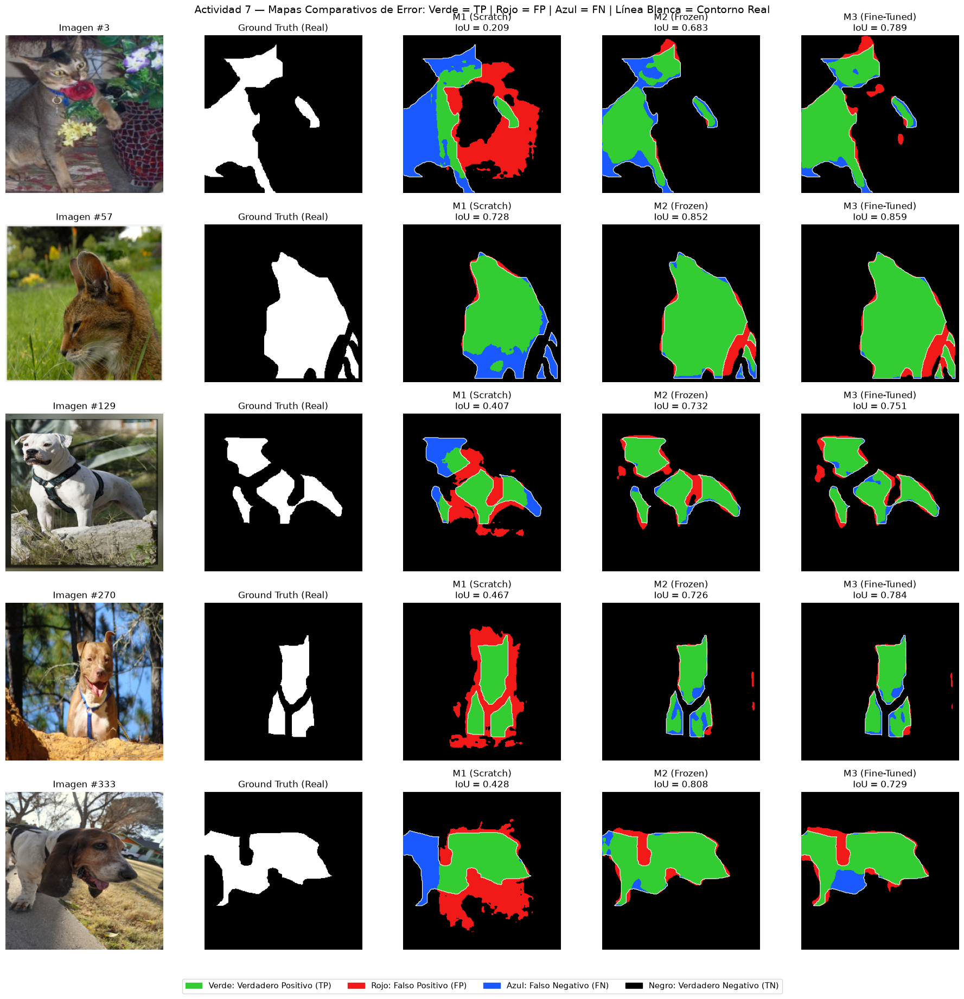

In [23]:
# Visualize_predictions para inspeccionar visualmente los mapas de error de M1, M2 y M3
visualize_predictions(
    {"M1 (Scratch)": m1, "M2 (Frozen)": m2, "M3 (Fine-Tuned)": m3},
    test_ds, VIS_IDX + [333],  # Inspeccionar 5 muestras representativas del conjunto de prueba
    title="Actividad 7 — Mapas Comparativos de Error: Verde = TP | Rojo = FP | Azul = FN | Línea Blanca = Contorno Real",
    fname="act7_visualize_predictions.png"
)

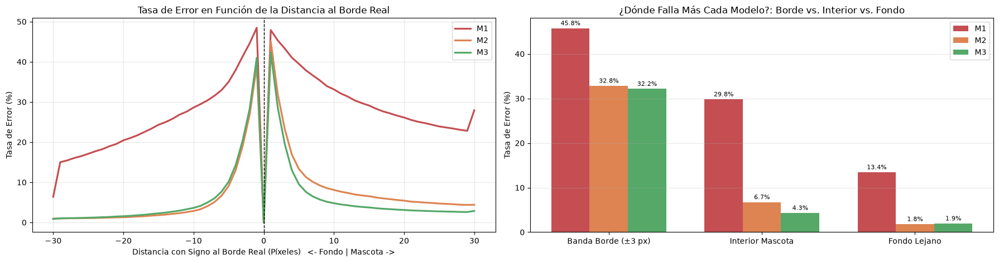

Desglose Cuantitativo del Error por Región Espacial:


,Error Banda Borde ±3px (%),Error Interior Mascota (%),Error Fondo Lejano (%),% de Errores Totales en el Borde
Modelo,,,,
M1,45.77,29.81,13.44,14.36
M2,32.84,6.73,1.80,40.43
M3,32.15,4.31,1.94,44.91


In [24]:
# Cuantificacion estricta de la pregunta del PDF: Tasa de error en la Banda del Borde vs. Interior vs. Fondo Lejano

def predict_probs(model, loader):  # Obtener mapa continuo de probabilidades para todo el dataloader
    model.eval()
    out = [] 
    with torch.no_grad():  # Sin gradientes
        for x, _ in loader: 
            with torch.autocast(device.type, enabled=USE_AMP):  # Precision mixta
                out.append(torch.sigmoid(model(x.to(device)).float())[:, 0].cpu().half())  # Predecir
    return torch.cat(out).numpy()  # Devuelve el arreglo NumPy

GTS = np.stack([test_ds[i][1][0].numpy().astype(bool) for i in range(len(test_ds))])  # Mascaras reales [N, 256, 256]
SDIST = np.stack([ndimage.distance_transform_edt(g) - ndimage.distance_transform_edt(~g) for g in GTS])  # Transformada de distancia con signo
PROBS = {k: predict_probs(m, test_loader) for k, m in [("M1", m1), ("M2", m2), ("M3", m3)]}  # Probabilidades

MAXD = 30  # Distancia máxima analizada (px)
bins = np.arange(-MAXD, MAXD + 1)  # Bins de distancia
sd_idx = (np.clip(np.round(SDIST), -MAXD, MAXD) + MAXD).astype(int).ravel()  # Bins planos
tot_bin = np.bincount(sd_idx, minlength=len(bins)) 

band = np.abs(SDIST) <= 3  # Banda de frontera (±3 px alrededor del borde real)
interior = SDIST > 3  # Interior del cuerpo de la mascota
exterior = SDIST < -3  # Fondo lejano

region_rows = []  # Lista de filas
fig, ax = plt.subplots(1, 2, figsize=(18, 4.8)) 

for k in ["M1", "M2", "M3"]:  # Recorrer modelos
    err = (PROBS[k] > 0.5) != GTS  # Mascara de errores booleanos
    rate = np.bincount(sd_idx, weights=err.ravel(), minlength=len(bins)) / np.maximum(tot_bin, 1)  # Tasa
    ax[0].plot(bins, rate * 100.0, lw=2.3, color=COLORS[k], label=f"{k}")  # Curva
    region_rows.append({
        "Modelo": k,
        "Error Banda Borde ±3px (%)": err[band].mean() * 100.0,
        "Error Interior Mascota (%)": err[interior].mean() * 100.0,
        "Error Fondo Lejano (%)": err[exterior].mean() * 100.0,
        "% de Errores Totales en el Borde": err[band].sum() / max(err.sum(), 1) * 100.0
    })

ax[0].axvline(0, color="k", ls="--", lw=1)  # Borde real
ax[0].set_xlabel("Distancia con Signo al Borde Real (Píxeles)   <- Fondo | Mascota ->")
ax[0].set_ylabel("Tasa de Error (%)") 
ax[0].set_title("Tasa de Error en Función de la Distancia al Borde Real")
ax[0].legend()
ax[0].grid(alpha=0.3)

df_reg = pd.DataFrame(region_rows).set_index("Modelo")  # DataFrame por region
RESULTS["borde_vs_interior"] = df_reg.round(3).to_dict(orient="index")  # Registrar

x_pos = np.arange(3)  # Posiciones
for i, k in enumerate(["M1", "M2", "M3"]):  # Recorrer modelos
    vals_r = df_reg.loc[k].values[:3]  # Extraer las 3 tasas de error
    b = ax[1].bar(x_pos + (i - 1) * 0.25, vals_r, 0.25, color=COLORS[k], label=k)  # Barras
    ax[1].bar_label(b, fmt="%.1f%%", fontsize=8, padding=2)  # Anotacion

ax[1].set_xticks(x_pos)  # Marcas
ax[1].set_xticklabels(["Banda Borde (±3 px)", "Interior Mascota", "Fondo Lejano"])  # Etiquetas
ax[1].set_ylabel("Tasa de Error (%)")
ax[1].set_title("¿Dónde Falla Más Cada Modelo?: Borde vs. Interior vs. Fondo")
ax[1].legend()
ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
save_fig("act7_bordes_vs_interior.png")
plt.show()

print("Desglose Cuantitativo del Error por Región Espacial:")
display(df_reg.round(2))
save_results()

**Mapas de Error:** 
> En las muestras mostradas, M3 tiene menos zonas de error que M1, aunque no las elimina por completo. Los colores permiten distinguir falsos positivos y falsos negativos y comparar visualmente sus ubicaciones.


**Borde vs. Interior:** 
>   - En el desglose cuantitativo, el error de M3 fue de 32.15% en la banda de borde y de 4.31% en el interior de la mascota. El 44.91% de sus errores cayó en la banda de borde; es una proporción importante, pero no una mayoría. Esto sugiere que el contorno sigue siendo una zona difícil para el modelo.

### **¿Dónde falla más cada modelo: en el interior de la región o en los bordes?**

> - En las muestras inspeccionadas se ven errores cerca de la transición entre la mascota y el fondo. El desglose por regiones muestra que el interior no es perfecto: el error interior es mayor en M1 (29.81%) que en M2 (6.73%) y M3 (4.31%).


### **¿A qué atribuyes esa diferencia?**

>   - **Ambigüedad Visual y Pelaje:** En las fronteras de los animales existen pelos individuales y zonas semi-transparentes donde determinar la frontera exacta píxel a píxel es complejo.
>   - **Resolución y contornos:** El *downsampling* reduce el detalle espacial disponible; las *skip connections* llevan parte de esa información al decoder, aunque no aseguran una reconstrucción exacta del borde.
>   - **Diferencia entre modelos:** En esta evaluación M1 tuvo más error interior que M2 y M3. M3 también conserva errores de borde y de fondo, por lo que no diría que sus errores quedan confinados a una franja estrecha.

## **Preguntas de Investigación**

### **1 - Entrenar Usando Solo `BCEWithLogitsLoss` sin Dice**

In [25]:
# Ejecutar Experimento R1: Entrenar U-Net con puramente BCEWithLogitsLoss sin Dice
set_seed(42) 
r1 = UNet(in_channels=3, num_classes=1).to(device)  # Instanciar UNet idéntica
crit_bce = nn.BCEWithLogitsLoss()  # Usar solo BCEWithLogitsLoss
opt_r1 = optim.Adam(r1.parameters(), lr=1e-3)  # Mismo optimizador Adam lr=1e-3

t_start = time.time()  
hist_r1 = train_seg(r1, train_loader, test_loader, crit_bce, opt_r1, EPOCHS, "R1_Pure_BCE", new_writer("R1_BCE_only"))  # Train
time_r1 = time.time() - t_start

ev_r1 = evaluate(r1, test_loader)  # Evaluación final en el test set completo
PROBS["R1"] = predict_probs(r1, test_loader) 
RESULTS["R1"] = {"hist": hist_r1, "time": time_r1, "test": ev_r1}
save_results()  

# Generar tabla comparativa directa entre M1 (BCE + Dice) y R1 (Solo BCE)
comp_r1 = pd.DataFrame({"M1 (BCE + Dice)": RESULTS["M1"]["test"], "R1 (Solo BCE)": ev_r1}).T[["iou", "dice", "acc", "precision", "recall"]]  # DF
print("\nComparativa Directa: M1 (BCEDiceLoss) vs. R1 (Pura BCEWithLogitsLoss):") 
display(comp_r1.round(4))

[R1_Pure_BCE] Época 1/5 | Train Loss: 0.5625 IoU: 0.1043 Dice: 0.1686 | Test Loss: 0.5560 IoU: 0.4105 Dice: 0.5820 | Tiempo: 107.5s
[R1_Pure_BCE] Época 2/5 | Train Loss: 0.4577 IoU: 0.4602 Dice: 0.6273 | Test Loss: 0.4341 IoU: 0.4817 Dice: 0.6502 | Tiempo: 106.9s
[R1_Pure_BCE] Época 3/5 | Train Loss: 0.4417 IoU: 0.4651 Dice: 0.6336 | Test Loss: 0.4454 IoU: 0.4858 Dice: 0.6539 | Tiempo: 107.0s
[R1_Pure_BCE] Época 4/5 | Train Loss: 0.4331 IoU: 0.4632 Dice: 0.6315 | Test Loss: 0.4436 IoU: 0.4257 Dice: 0.5972 | Tiempo: 108.6s
[R1_Pure_BCE] Época 5/5 | Train Loss: 0.4335 IoU: 0.4723 Dice: 0.6399 | Test Loss: 0.5309 IoU: 0.5026 Dice: 0.6690 | Tiempo: 108.4s

Comparativa Directa: M1 (BCEDiceLoss) vs. R1 (Pura BCEWithLogitsLoss):


,iou,dice,acc,precision,recall
M1 (BCE + Dice),0.5086,0.6742,0.8013,0.6632,0.6856
R1 (Solo BCE),0.5026,0.6690,0.7725,0.5934,0.7667


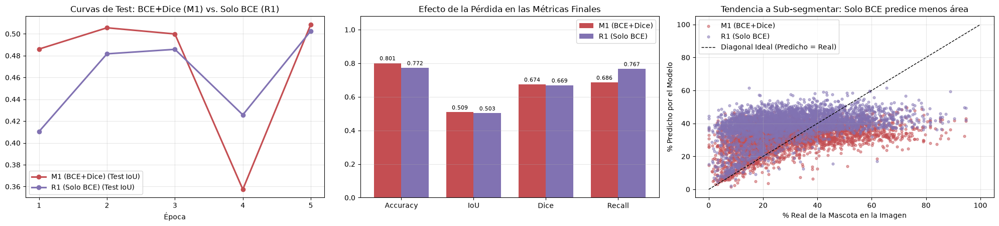

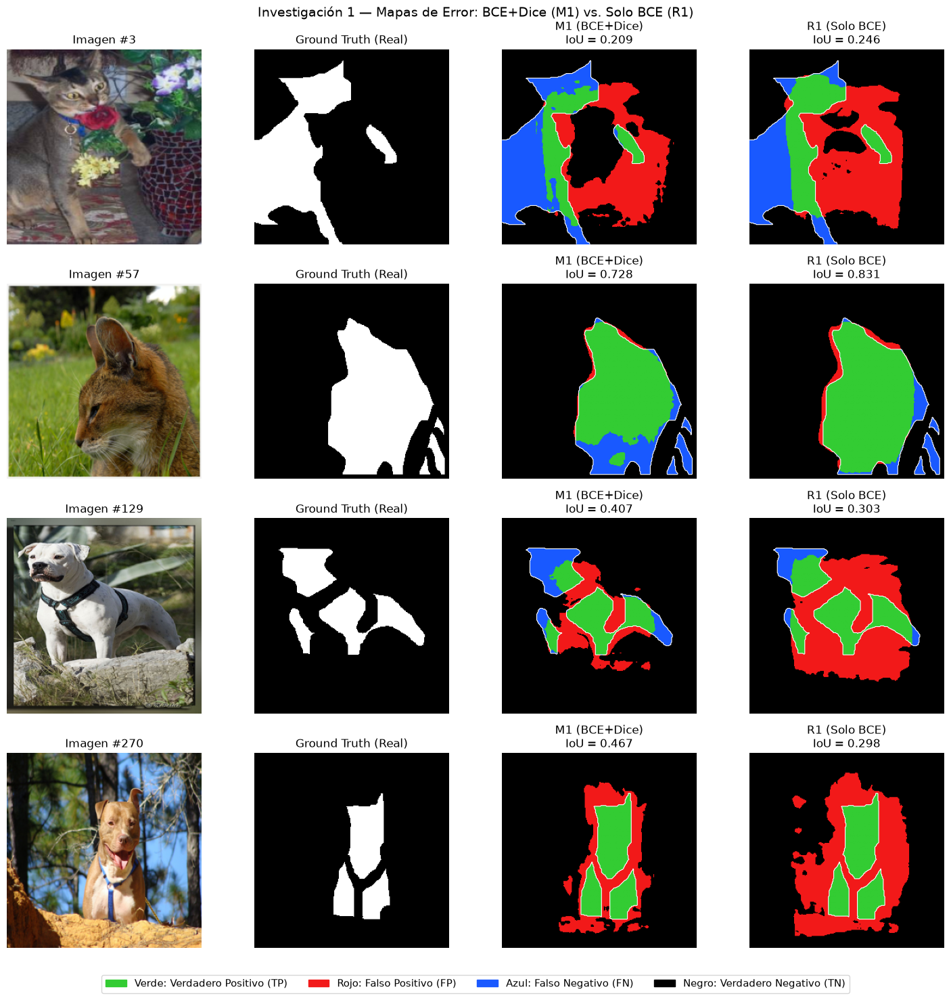

UNet(
  (encoders): ModuleList(
    (0): DoubleConv(
      (net): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (1): DoubleConv(
      (net): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_ru

In [26]:
# Analizar la tendencia a sub-segmentar u omitir regiones pequeñas cuando se usa solo BCE
pred_frac_m1 = (PROBS["M1"] > 0.5).mean(axis=(1, 2))  # % predicho por M1
pred_frac_r1 = (PROBS["R1"] > 0.5).mean(axis=(1, 2))  # % predicho por R1
gt_frac_all = GTS.mean(axis=(1, 2))  # % real

fig, ax = plt.subplots(1, 3, figsize=(20, 4.6))

for key, h in [("M1 (BCE+Dice)", hist_m1), ("R1 (Solo BCE)", hist_r1)]:  
    col = COLORS["M1"] if "M1" in key else COLORS["R1"]  
    ax[0].plot(ep, h["test_iou"], "o-", color=col, lw=2.3, label=f"{key} (Test IoU)")  # Curva IoU

ax[0].set_xlabel("Época")  
ax[0].set_title("Curvas de Test: BCE+Dice (M1) vs. Solo BCE (R1)") 
ax[0].set_xticks(ep) 
ax[0].legend()  
ax[0].grid(alpha=0.3)  

metrics_r1_names = ["Accuracy", "IoU", "Dice", "Recall"]  # Nombres
for i, (lab, ev_d) in enumerate([("M1 (BCE+Dice)", RESULTS["M1"]["test"]), ("R1 (Solo BCE)", ev_r1)]):  # Recorrer
    col = COLORS["M1"] if "M1" in lab else COLORS["R1"]
    vals_m = [ev_d[k] for k in ["acc", "iou", "dice", "recall"]] 
    b = ax[1].bar(np.arange(4) + (i - 0.5) * 0.38, vals_m, 0.38, color=col, label=lab)
    ax[1].bar_label(b, fmt="%.3f", fontsize=8, padding=2)  # Anotacion

ax[1].set_xticks(np.arange(4))  
ax[1].set_xticklabels(metrics_r1_names)
ax[1].set_ylim(0, 1.08)  # Rango
ax[1].set_title("Efecto de la Pérdida en las Métricas Finales")  
ax[1].legend() 
ax[1].grid(axis="y", alpha=0.3) 

ax[2].scatter(gt_frac_all * 100, pred_frac_m1 * 100, s=12, alpha=0.5, color=COLORS["M1"], label="M1 (BCE+Dice)")  # Scatter M1
ax[2].scatter(gt_frac_all * 100, pred_frac_r1 * 100, s=12, alpha=0.5, color=COLORS["R1"], label="R1 (Solo BCE)")  # Scatter R1
ax[2].plot([0, 100], [0, 100], "k--", lw=1, label="Diagonal Ideal (Predicho = Real)") 
ax[2].set_xlabel("% Real de la Mascota en la Imagen")  
ax[2].set_ylabel("% Predicho por el Modelo") 
ax[2].set_title("Tendencia a Sub-segmentar: Solo BCE predice menos área")  
ax[2].legend()
ax[2].grid(alpha=0.3) 
plt.tight_layout()
save_fig("inv1_bce_vs_bcedice.png")
plt.show()

# Visualizar la comparacion entre M1 y R1
visualize_predictions({"M1 (BCE+Dice)": m1, "R1 (Solo BCE)": r1}, test_ds, VIS_IDX, title="Investigación 1 — Mapas de Error: BCE+Dice (M1) vs. Solo BCE (R1)", fname="inv1_pred.png")
r1.cpu()  # Liberar VRAM de R1

### **¿Qué pasa con las métricas?** 

> **Comportamiento Cualitativo de las Métricas:**
> En las salidas guardadas, M1 (BCE + Dice) obtuvo IoU 0.5086, Dice 0.6742, precisión 0.6632 y recall 0.6856. R1 (solo BCE) obtuvo IoU 0.5026, Dice 0.6690, precisión 0.5934 y recall 0.7667. Las diferencias de IoU y Dice son pequeñas; R1 tuvo menor precisión y mayor recall, lo que coincide con más falsos positivos y menos falsos negativos en el balance global. Una sola corrida no permite separar el efecto de la pérdida de la variación aleatoria, y las cifras deben actualizarse con el test completo.

> **Explicación del Fenómeno:**
> BCEWithLogitsLoss calcula la pérdida por píxel; DiceLoss añade un término relacionado con el solapamiento global. La comparación permite observar cómo cambiaron las métricas al quitar Dice en esta configuración, pero no demuestra que la pérdida combinada vaya a ser mejor en todos los conjuntos.

> **Otras opciones ante el desbalance:**
> 1. Combinar BCE con pérdidas de solapamiento como Dice o IoU.
> 2. **BCE Ponderada (*Weighted BCE*):** Asignar un peso ponderador ($	ext{pos\_weight} > 1$) a la clase positiva para multiplicar los gradientes correspondientes a las lesiones u objetos minoritarios.
> 3. **Focal Loss:** Incorporar un factor modulador $\gamma$ que reduce la influencia de los píxeles de fondo fácilmente clasificables y focaliza la actualización del modelo en los píxeles difíciles y ambiguos.
> 4. **Pérdidas Orientadas a Contornos:** Emplear pérdidas basadas en fronteras (*Boundary Loss* o *Hausdorff Loss*), que ponderan la penalización según la distancia métrica a la superficie del tejido de interés.

### **2 - Eliminar las Skip Connections de ResNetUNet**

In [27]:
# Definir la clase ResNetUNetNoSkips eliminando las conexiones de salto
class ResNetUNetNoSkips(ResNetUNet): 
    def __init__(self, num_classes=1):  # Constructor
        super().__init__(num_classes)  # Inicializar la superclase ResNetUNet
        # Reconstruir el decoder ajustando canales para recibir UNICAMENTE la salida inferior sin concatenar skips
        self.dec4 = DoubleConv(512, 256)  # Solo recibe up(s4) [512] -> 256
        self.dec3 = DoubleConv(256, 128)  # Solo recibe up(d4) [256] -> 128
        self.dec2 = DoubleConv(128, 64)   # Solo recibe up(d3) [128] -> 64
        self.dec1 = DoubleConv(64, 64)    # Solo recibe up(d2) [64] -> 64

    # Metodo forward omitiendo las concatenaciones torch.cat con s0, s1, s2, s3
    def forward(self, x): 
        s4 = self.enc4(self.enc3(self.enc2(self.enc1(self.enc0(x)))))  # Pasar directo al bottleneck s4 (8x8, 512c)
        d4 = self.dec4(self.up(s4))  # Upsampling a 16x16 sin skip s3
        d3 = self.dec3(self.up(d4))  # Upsampling a 32x32 sin skip s2
        d2 = self.dec2(self.up(d3))  # Upsampling a 64x64 sin skip s1
        d1 = self.dec1(self.up(d2))  # Upsampling a 128x128 sin skip s0
        return self.head(self.dec0(self.up(d1)))  # Proyeccion final a 256x256 -> logits

# Instanciar y entrenar el Modelo R2 (ResNetUNet SIN Skip Connections)
set_seed(42)
r2 = ResNetUNetNoSkips().to(device)  # Instanciar R2 en GPU
freeze_encoder(r2, True)  # Congelar encoder ResNet-18 como en M2
opt_r2 = optim.Adam([p for p in r2.parameters() if p.requires_grad], lr=1e-3)  # Mismo optimizador Adam lr=1e-3

t_start = time.time() 
hist_r2 = train_seg(r2, train_loader, test_loader, criterion, opt_r2, EPOCHS, "R2_No_Skips", new_writer("R2_no_skips"))  # Train
time_r2 = time.time() - t_start

ev_r2 = evaluate(r2, test_loader)  # Evaluacion final en test set completo
PROBS["R2"] = predict_probs(r2, test_loader) 

RESULTS["R2"] = {"hist": hist_r2, "time": time_r2, "test": ev_r2}  # Registrar resultados
save_results()

# Mostrar tabla comparativa directa entre M2 (Con Skips) y R2 (Sin Skips)
comp_r2 = pd.DataFrame({"M2 ResNetUNet (Con Skips)": RESULTS["M2"]["test"], "R2 ResNetUNet (SIN Skips)": ev_r2}).T[["iou", "dice", "acc", "precision", "recall"]]  # DF
print("\nComparativa Directa: M2 (Con Skip Connections) vs. R2 (Sin Skip Connections):")
display(comp_r2.round(4)) 

[R2_No_Skips] Época 1/5 | Train Loss: 0.7684 IoU: 0.5995 Dice: 0.7466 | Test Loss: 0.6697 IoU: 0.6666 Dice: 0.7999 | Tiempo: 45.4s
[R2_No_Skips] Época 2/5 | Train Loss: 0.5631 IoU: 0.6764 Dice: 0.8059 | Test Loss: 0.6286 IoU: 0.6136 Dice: 0.7605 | Tiempo: 42.6s
[R2_No_Skips] Época 3/5 | Train Loss: 0.5272 IoU: 0.6909 Dice: 0.8162 | Test Loss: 0.5015 IoU: 0.7068 Dice: 0.8282 | Tiempo: 41.8s
[R2_No_Skips] Época 4/5 | Train Loss: 0.4858 IoU: 0.7113 Dice: 0.8306 | Test Loss: 0.4886 IoU: 0.7164 Dice: 0.8348 | Tiempo: 42.4s
[R2_No_Skips] Época 5/5 | Train Loss: 0.4677 IoU: 0.7206 Dice: 0.8369 | Test Loss: 0.4695 IoU: 0.7260 Dice: 0.8412 | Tiempo: 42.2s

Comparativa Directa: M2 (Con Skip Connections) vs. R2 (Sin Skip Connections):


,iou,dice,acc,precision,recall
M2 ResNetUNet (Con Skips),0.8426,0.9146,0.9494,0.9261,0.9033
R2 ResNetUNet (SIN Skips),0.7260,0.8412,0.9058,0.8509,0.8318


Píxeles con Probabilidad Incierta (0.1 < P < 0.9): M2 (Con Skips) = 9.84% | R2 (Sin Skips) = 14.63%


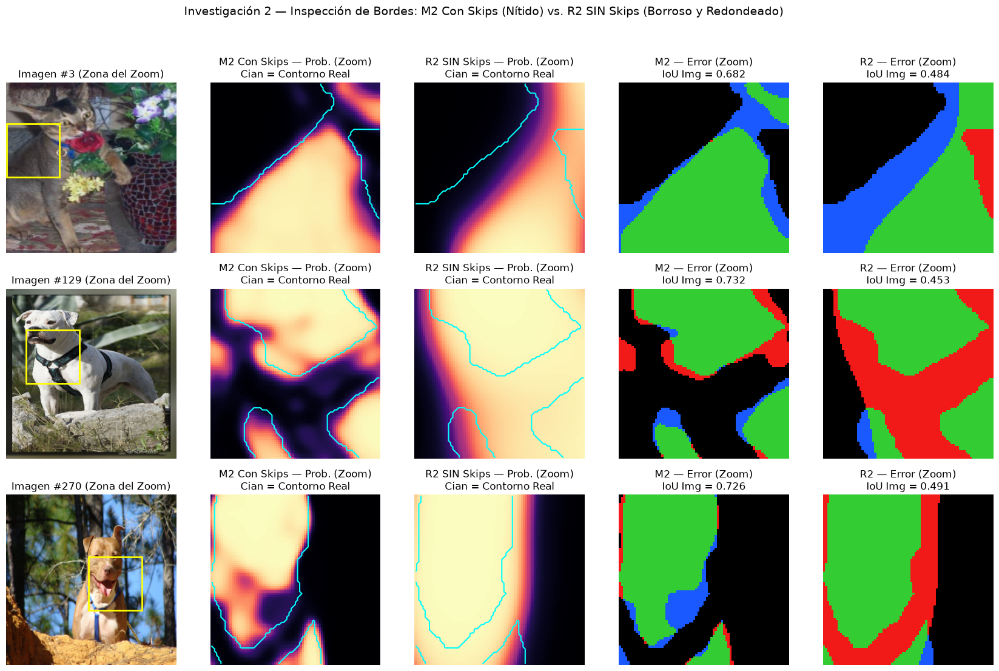

ResNetUNetNoSkips(
  (enc0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (enc1): Sequential(
    (0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(6

In [28]:
# Analisis detallado del impacto de eliminar las Skip Connections en los bordes del objeto
def soft_edge_width(probs, lo=0.1, hi=0.9):  # Funcion para medir el % de pixeles con incertidumbre (bordes borrosos)
    return ((probs > lo) & (probs < hi)).mean() * 100.0  # Porcentaje

px_unc_m2 = soft_edge_width(PROBS["M2"].astype(np.float32))  # Incertidumbre M2
px_unc_r2 = soft_edge_width(PROBS["R2"].astype(np.float32))  # Incertidumbre R2

print(f"Píxeles con Probabilidad Incierta (0.1 < P < 0.9): M2 (Con Skips) = {px_unc_m2:.2f}% | R2 (Sin Skips) = {px_unc_r2:.2f}%") 

# Graficar zoom de alta resolucion sobre los bordes de la mascara para evidenciar la borrosidad de R2
fig, axes = plt.subplots(3, 5, figsize=(21, 12.5))
for r, idx in enumerate([3, 129, 270]):  # Iterar sobre 3 muestras
    x, y = test_ds[idx]  # Cargar imagen y mascara
    gt = y[0].numpy()  # Ground Truth
    pts = np.argwhere(gt.astype(bool) ^ ndimage.binary_erosion(gt.astype(bool)))  # Extraer contorno real
    cy, cx = np.clip(pts[len(pts) // 3], 40, IMG_SIZE - 40)  # Seleccionar centro del zoom
    win = (slice(cy - 40, cy + 40), slice(cx - 40, cx + 40))  # Ventana de zoom 80x80
    
    axes[r, 0].imshow(denorm(x))  # Entrada RGB
    axes[r, 0].add_patch(plt.Rectangle((cx - 40, cy - 40), 80, 80, fill=False, color="yellow", lw=2))
    axes[r, 0].set_title(f"Imagen #{idx} (Zona del Zoom)")
    
    for c, key in enumerate(["M2", "R2"]):  # Recorrer M2 y R2
        prob = PROBS[key][idx].astype(np.float32)  # Probabilidades
        axes[r, 1 + c].imshow(prob[win], cmap="magma", vmin=0, vmax=1)  # Mapa continuo de probabilidades
        axes[r, 1 + c].contour(gt[win], levels=[0.5], colors="cyan", linewidths=1.5)  # Contorno real en cian
        axes[r, 1 + c].set_title(f"{key} {'Con' if key=='M2' else 'SIN'} Skips — Prob. (Zoom)\nCian = Contorno Real")
        axes[r, 3 + c].imshow(error_rgb((prob > 0.5).astype(int), gt.astype(int))[win])  # Mapa de error
        axes[r, 3 + c].set_title(f"{key} — Error (Zoom)\nIoU Img = {iou_np(prob > 0.5, gt):.3f}")

for a in axes.ravel():
    a.axis("off")
plt.suptitle("Investigación 2 — Inspección de Bordes: M2 Con Skips (Nítido) vs. R2 SIN Skips (Borroso y Redondeado)", fontsize=14)
save_fig("inv2_bordes_skips.png")
plt.show()
r2.cpu()


## **¿Qué observas visualmente en los bordes de las predicciones?**

**Impacto en las Métricas de Solapamiento (IoU / Dice):**
> En las salidas guardadas, R2 (sin *skip connections*) obtuvo IoU 0.7260 y Dice 0.8412; M2 (con *skip connections*) obtuvo 0.8426 y 0.9146. La diferencia respalda la utilidad de esas conexiones en esta arquitectura, aunque debe recalcularse con el test completo.

**Observación Visual en los Bordes:**
>   - En las imágenes mostradas, R2 tiene bordes más suavizados en algunos ejemplos, mientras que M2 conserva mejor ciertos detalles del contorno. La explicación probable es que las conexiones llevan mapas espaciales del encoder al decoder; las imágenes son ilustrativas y no bastan por sí solas para generalizar a todo el test.
>   - La diferencia cuantitativa entre M2 y R2 se resume en las métricas anteriores.

**Análisis de la Incertidumbre Espacial en Fronteras:** 
> Las probabilidades intermedias cerca de los bordes pueden indicar incertidumbre, pero para comparar formalmente esa franja habría que definir el rango de probabilidades y medirlo de forma consistente.

### **3 - Curva IoU frente al Umbral de Binarización**

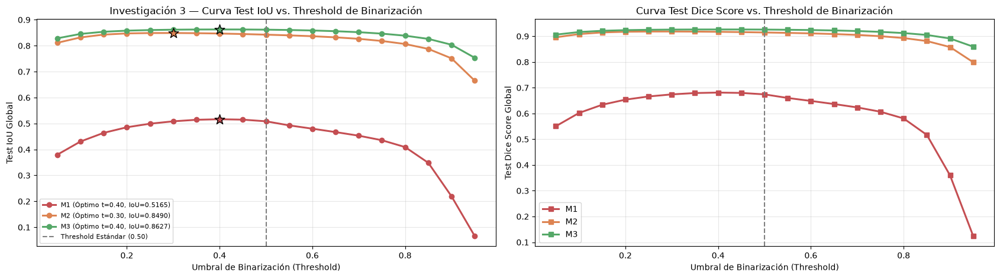

Tabla Resumen del Umbral Óptimo de Binarización por Modelo:


,Threshold Óptimo,Test IoU Óptimo,Test IoU @ 0.50,Ganancia de IoU
Modelo,,,,
M1,0.4,0.516468,0.508520,+0.79 pts
M2,0.3,0.849015,0.842576,+0.64 pts
M3,0.4,0.862677,0.861874,+0.08 pts


In [ ]:
# Barrido estricto de umbrales de binarización de 0.05 a 0.95 en pasos de 0.05
ths = np.round(np.arange(0.05, 0.951, 0.05), 2)  # Definir vector de 19 umbrales
sweep = {}  # Diccionario para almacenar resultados

for k in ["M1", "M2", "M3"]:  # Recorrer los 3 modelos principales
    ious, dices = [], [] 
    for t in ths:  # Probar cada umbral t
        p = PROBS[k] > t  # Binarizar probabilidades con el umbral t
        tp_ = (p & GTS).sum()  # Verdaderos Positivos globales
        fp_ = (p & ~GTS).sum()  # Falsos Positivos globales
        fn_ = (~p & GTS).sum()  # Falsos Negativos globales
        ious.append(tp_ / (tp_ + fp_ + fn_ + 1e-6))  # IoU global
        dices.append(2.0 * tp_ / (2.0 * tp_ + fp_ + fn_ + 1e-6))  # Dice global
    sweep[k] = (np.array(ious), np.array(dices))

rows_th = []
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))

for k, (ious, dices) in sweep.items():  # Recorrer resultados por modelo
    best_idx = int(np.argmax(ious))  # Encontrar el indice del IoU maximo
    best_t = ths[best_idx]  # Umbral optimo
    best_iou = ious[best_idx]  # IoU maximo
    iou_def = ious[list(ths).index(0.5)]  # IoU con umbral por defecto 0.5
    gain = (best_iou - iou_def) * 100.0  # Ganancia en puntos de IoU
    


    rows_th.append({"Modelo": k, "Threshold Óptimo": best_t, "Test IoU Óptimo": best_iou, "Test IoU @ 0.50": iou_def, "Ganancia de IoU": f"+{gain:.2f} pts"})
    
    ax[0].plot(ths, ious, "o-", color=COLORS[k], lw=2.2, label=f"{k} (Óptimo t={best_t:.2f}, IoU={best_iou:.4f})")  # Curva IoU
    ax[0].scatter([best_t], [best_iou], s=160, marker="*", color=COLORS[k], edgecolor="k", zorder=5)  # Estrella en el optimo
    ax[1].plot(ths, dices, "s-", color=COLORS[k], lw=2.2, label=f"{k}")  # Curva Dice

ax[0].axvline(0.5, color="gray", ls="--", label="Threshold Estándar (0.50)")
ax[0].set_xlabel("Umbral de Binarización (Threshold)")
ax[0].set_ylabel("Test IoU Global")
ax[0].set_title("Investigación 3 — Curva Test IoU vs. Threshold de Binarización")
ax[0].legend(fontsize=8)
ax[0].grid(alpha=0.3)

ax[1].axvline(0.5, color="gray", ls="--") 
ax[1].set_xlabel("Umbral de Binarización (Threshold)")
ax[1].set_ylabel("Test Dice Score Global")
ax[1].set_title("Curva Test Dice Score vs. Threshold de Binarización")
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
save_fig("inv3_iou_vs_threshold.png")
plt.show()

df_th = pd.DataFrame(rows_th).set_index("Modelo")  
RESULTS["threshold"] = df_th.to_dict(orient="index")
save_results()

print("Tabla Resumen del Umbral Óptimo de Binarización por Modelo:")
display(df_th)

## **¿Cuál sería el threshold óptimo?**

- En la tabla, el umbral que maximiza IoU sobre el test fue 0.4 para M1, 0.3 para M2 y 0.4 para M3. Como se escogió mirando las etiquetas del propio test, estos máximos son descriptivos y no deben presentarse como una evaluación independiente ni como evidencia de calibración.

- Para elegir el umbral de uso, ajústalo en validación y luego reporta el resultado final del test con ese valor ya fijado. La curva muestra cuánto cambia IoU al variar el corte, pero no demuestra por sí sola robustez.

### **4 - Data Augmentation en Imágenes Médicas**

En imágenes médicas (resonancias magnéticas RMN, tomografías axiales TAC, microscopía):
- **Deformación Elástica:** Genera un campo de desplazamiento vectorial estocástico $(\Delta x, \Delta y)$ suavizado mediante un filtro gaussiano con desviación $\sigma$ y escalado por un factor $\alpha$. Simula las deformaciones elásticas naturales de los tejidos biológicos y la variabilidad anatómica entre pacientes. 

El campo de deformación se debe aplicar en **estricta sincronía tanto a la imagen como a la máscara** (usando interpolación `NEAREST` para la máscara).

- **Corrección Gamma ($I' = I^\gamma$):** Aplica transformaciones no lineales de intensidad para simular diferencias en el contraste del tejido y variaciones de calibración entre distintos escáneres médicos. Solo afecta a la imagen RGB.

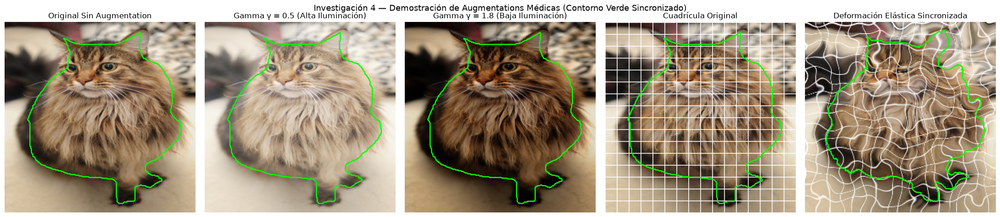

In [30]:
# Definir la subclase PetSegDatasetMedAug incorporando Deformación Elástica y Corrección Gamma
class PetSegDatasetMedAug(PetSegDataset): 
    def __init__(self, names, p_gamma=0.5, p_elastic=0.5, alpha=200.0, sigma=8.0, **kw):  # Constructor
        super().__init__(names, **kw)  # Inicializa la clase padre
        self.p_gamma, self.p_elastic, self.alpha, self.sigma = p_gamma, p_elastic, alpha, sigma  # Parametros

    # Funcion para aplicar Correccion Gamma estocastica a la imagen RGB
    def gamma_transform(self, img, g=None):
        g_val = g if g is not None else random.uniform(0.6, 1.6)  # Sortea gamma
        return TF.adjust_gamma(img, g_val)  # Aplica I' = I^gamma

    # Funcion para aplicar Deformacion Elastica sincronizada a la imagen y a la mascara
    def elastic_transform(self, img, mask):
        a, m = np.array(img, dtype=np.float32), np.array(mask)  # Convertir a arreglos NumPy
        h, w = m.shape  # Extraer dimensiones
        
        # Generar campo de desplazamiento gaussiano estocástico suavizado
        dx = ndimage.gaussian_filter(np.random.uniform(-1, 1, (h, w)), self.sigma) * self.alpha  # Desplazamiento X
        dy = ndimage.gaussian_filter(np.random.uniform(-1, 1, (h, w)), self.sigma) * self.alpha  # Desplazamiento Y
        
        yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
        coords = [yy + dy, xx + dx]  # Aplicar deformacion a las coordenadas
        
        # Remapear imagen RGB con BILINEAR (order=1) y mascara con NEAREST (order=0)
        a_def = np.stack([ndimage.map_coordinates(a[..., c], coords, order=1, mode="reflect") for c in range(3)], -1)  # RGB
        m_def = ndimage.map_coordinates(m, coords, order=0, mode="reflect")  # Mascara NEAREST
        
        return Image.fromarray(np.clip(a_def, 0, 255).astype(np.uint8)), Image.fromarray(m_def.astype(np.uint8))  # PIL

    # Sobrescribir el metodo extra_aug para inyectar las transformaciones medicas
    def extra_aug(self, img, mask):
        if random.random() < self.p_gamma:  # Probabilidad p_gamma
            img = self.gamma_transform(img)  # Aplicar gamma
        if random.random() < self.p_elastic:  # Probabilidad p_elastic
            img, mask = self.elastic_transform(img, mask)  # Aplicar deformacion elastica sincronizada
        return img, mask  # Devolver el par modificado

# Visualizar el efecto de las Augmentations Médicas sobre una muestra real
aug_ds_demo = PetSegDatasetMedAug(train_names, train=True)  # Instancia demo
base_img, base_trimap = aug_ds_demo.load_raw(42)
base_img = base_img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)  # Resize
base_mask = Image.fromarray((np.array(base_trimap) == 1).astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)  # Resize

# Generar imagen con cuadricula para evidenciar la deformacion elastica
grid_img = np.array(base_img).copy()  
grid_img[::16, :, :] = 255; grid_img[:, ::16, :] = 255  # Dibujar cuadricula blanca
np.random.seed(1) 
el_img, el_mask = aug_ds_demo.elastic_transform(Image.fromarray(grid_img), base_mask)  # Deformar

views = [ 
    ("Original Sin Augmentation", base_img, base_mask),  
    ("Gamma γ = 0.5 (Alta Iluminación)", aug_ds_demo.gamma_transform(base_img, 0.5), base_mask), 
    ("Gamma γ = 1.8 (Baja Iluminación)", aug_ds_demo.gamma_transform(base_img, 1.8), base_mask),  
    ("Cuadrícula Original", Image.fromarray(grid_img), base_mask),  
    ("Deformación Elástica Sincronizada", el_img, el_mask) 
]  

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8)) 
for a, (t, im, mk) in zip(axes, views):
    a.imshow(im)
    a.contour(np.array(mk), levels=[0.5], colors="lime", linewidths=1.8)  # Contorno de la mascara sincronizada en verde
    a.set_title(t)
    a.axis("off")
plt.suptitle("Investigación 4 — Demostración de Augmentations Médicas (Contorno Verde Sincronizado)", fontsize=13) 
plt.tight_layout()
save_fig("inv4_augmentations.png") 
plt.show()

[R4_Medical_Aug] Época 1/5 | Train Loss: 0.6612 IoU: 0.6738 Dice: 0.8010 | Test Loss: 0.4074 IoU: 0.8080 Dice: 0.8938 | Tiempo: 51.6s
[R4_Medical_Aug] Época 2/5 | Train Loss: 0.4320 IoU: 0.7534 Dice: 0.8580 | Test Loss: 0.3208 IoU: 0.8195 Dice: 0.9008 | Tiempo: 51.7s
[R4_Medical_Aug] Época 3/5 | Train Loss: 0.3818 IoU: 0.7779 Dice: 0.8742 | Test Loss: 0.2937 IoU: 0.8277 Dice: 0.9057 | Tiempo: 52.1s
[R4_Medical_Aug] Época 4/5 | Train Loss: 0.3593 IoU: 0.7882 Dice: 0.8806 | Test Loss: 0.3487 IoU: 0.8039 Dice: 0.8913 | Tiempo: 52.1s
[R4_Medical_Aug] Época 5/5 | Train Loss: 0.3370 IoU: 0.8006 Dice: 0.8884 | Test Loss: 0.2604 IoU: 0.8471 Dice: 0.9172 | Tiempo: 52.7s
Prueba de Robustez de M2 vs. R4 Ante Variaciones de Iluminación en el Test Set:


,M2 (Sin Aug),R4 (Con Aug Médica),Ganancia (R4 vs M2)
γ = 0.5 (Alta Ilum.),0.8332,0.8383,0.5107
γ = 1.0 (Normal),0.8426,0.8471,0.4536
γ = 2.0 (Baja Ilum.),0.8252,0.8333,0.8088


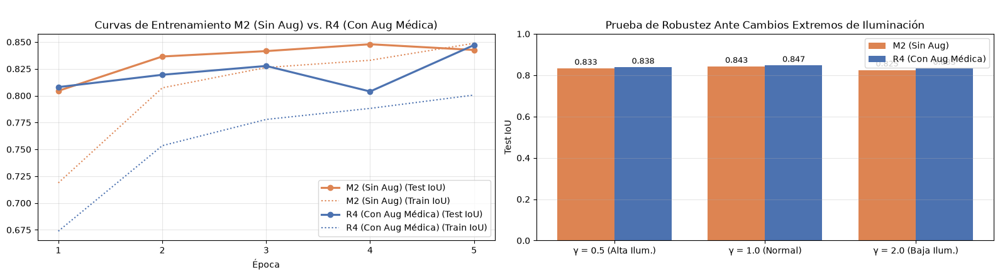

ResNetUNet(
  (enc0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (enc1): Sequential(
    (0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=

In [31]:
# Entrenar el Modelo R4 (ResNetUNet + Augmentations Médicas) por 5 épocas
set_seed(42)
aug_train_ds = PetSegDatasetMedAug(train_names, train=True)  # Dataset con augmentations medicas
aug_train_loader = DataLoader(aug_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)  # Loader

r4 = ResNetUNet().to(device)  # Instanciar ResNetUNet idéntica a M2
freeze_encoder(r4, True)  # Congelar encoder como en M2
opt_r4 = optim.Adam([p for p in r4.parameters() if p.requires_grad], lr=1e-3)  # Mismo optimizador Adam lr=1e-3

t_start = time.time()  
hist_r4 = train_seg(r4, aug_train_loader, test_loader, criterion, opt_r4, EPOCHS, "R4_Medical_Aug", new_writer("R4_medical_aug"))  # Train
time_r4 = time.time() - t_start  

# Probar la robustez de M2 (Sin Aug) vs. R4 (Con Aug) ante cambios severos de iluminacion en el test set
class GammaTestDataset(PetSegDataset):  # Test dataset modificando la gamma
    def __init__(self, names, g):  # Constructor
        super().__init__(names, train=False)  # Test
        self.g = g  # Gamma
    def load_raw(self, idx):  # Sobrescribir carga
        img, tri = super().load_raw(idx)  # Cargar
        return TF.adjust_gamma(img, self.g), tri  # Aplicar gamma fija a la imagen

rob_results = {}  # Resultados de robustez
for g_val in [0.5, 1.0, 2.0]:  # Iluminaciones: 0.5 (Sobreexpuesta), 1.0 (Normal), 2.0 (Subexpuesta)
    g_ld = DataLoader(GammaTestDataset(test_names, g_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)  # Loader
    rob_results[g_val] = {"M2 (Sin Aug)": evaluate(m2, g_ld)["iou"], "R4 (Con Aug Médica)": evaluate(r4, g_ld)["iou"]}  # Evaluar

RESULTS["R4"] = {"hist": hist_r4, "time": time_r4, "test": evaluate(r4, test_loader), "robustez_iou": {str(k): v for k, v in rob_results.items()}}
save_results() 

df_rob = pd.DataFrame(rob_results).T  # DataFrame
df_rob.index = [f"γ = {g} ({'Alta Ilum.' if g==0.5 else 'Normal' if g==1.0 else 'Baja Ilum.'})" for g in df_rob.index]  # Nombres
df_rob["Ganancia (R4 vs M2)"] = (df_rob["R4 (Con Aug Médica)"] - df_rob["M2 (Sin Aug)"]) * 100.0  # Ganancia

print("Prueba de Robustez de M2 vs. R4 Ante Variaciones de Iluminación en el Test Set:")
display(df_rob.round(4)) 

# Graficar la comparacion de robustez
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for key, h in [("M2 (Sin Aug)", hist_m2), ("R4 (Con Aug Médica)", hist_r4)]:
    col = COLORS["M2"] if "M2" in key else COLORS["R4"]
    ax[0].plot(ep, h["test_iou"], "o-", color=col, lw=2.3, label=f"{key} (Test IoU)")  # Test
    ax[0].plot(ep, h["train_iou"], ":", color=col, lw=1.5, label=f"{key} (Train IoU)")  # Train
ax[0].set_xlabel("Época")
ax[0].set_title("Curvas de Entrenamiento M2 (Sin Aug) vs. R4 (Con Aug Médica)")
ax[0].set_xticks(ep)  # Marcas
ax[0].legend()
ax[0].grid(alpha=0.3)

x_rob = np.arange(len(df_rob))  # Posiciones
for i, col_name in enumerate(["M2 (Sin Aug)", "R4 (Con Aug Médica)"]):  # Recorrer
    col_c = COLORS["M2"] if "M2" in col_name else COLORS["R4"]  # Color
    b = ax[1].bar(x_rob + (i - 0.5) * 0.38, df_rob[col_name], 0.38, color=col_c, label=col_name)  # Barras
    ax[1].bar_label(b, fmt="%.3f", fontsize=9, padding=2)  # Anotacion

ax[1].set_xticks(x_rob)  # Marcas
ax[1].set_xticklabels(["γ = 0.5 (Alta Ilum.)", "γ = 1.0 (Normal)", "γ = 2.0 (Baja Ilum.)"])
ax[1].set_ylim(0, 1.0)
ax[1].set_ylabel("Test IoU")
ax[1].set_title(f"\nPrueba de Robustez Ante Cambios Extremos de Iluminación")
ax[1].legend()
ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
save_fig("inv4_impacto_aug.png")
plt.show()
r4.cpu()

**Aumentación aplicada en R4:** 
- R4 usa deformaciones elásticas y variaciones gamma durante el entrenamiento. Estas transformaciones cambian la geometría y la intensidad de las imágenes; su efecto sobre la convergencia y las métricas debe interpretarse a partir de los resultados de las corridas.

**Robustez ante Perturbaciones de Iluminación (Variaciones Gamma):**
- La prueba compara las predicciones bajo cambios de intensidad simulados. Si R4 conserva mejor IoU en esas condiciones, eso sugiere mayor tolerancia a esas perturbaciones concretas; no equivale a demostrar robustez ante escáneres o datos médicos reales.

**Alcance de esta aumentación:**
- Aunque algunas transformaciones están inspiradas en aumentación médica, aquí se aplican a imágenes de mascotas. Para afirmar que funcionan en imágenes médicas habría que entrenar y evaluar con datos de ese dominio.


### **5 - Métrica Distancia de Hausdorff**

### **Definición Matemática y Diferencia Principal**
La **Distancia de Hausdorff (HD)** entre el contorno de la región predicha $(\partial)$ y el contorno real $(\partial)$ se define como:

$$
d_H(\partial P,\partial T)
=
\max\left(
\sup_{a\in\partial P}\inf_{b\in\partial T}\|a-b\|_2,\;
\sup_{b\in\partial T}\inf_{a\in\partial P}\|b-a\|_2
\right)
$$

Asimismo, se suele utilizar el **Percentil 95 de la Distancia de Hausdorff (HD95)** para mitigar el impacto de puntos extremadamente anómalos o ruido puntual en los contornos.

**¿Qué miden IoU y Dice?** 
- Evalúan el **solapamiento global de área o volumen** entre las regiones de interés. Si un modelo segmenta correctamente casi todo el cuerpo del objeto pero genera una pequeña región falsa aislada o un artefacto a distancia, el impacto en IoU y Dice será mínimo debido a la dominancia del área total acertada.

**¿Qué mide la Distancia de Hausdorff que IoU y Dice no capturan?** 
- HD mide la mayor separación entre puntos de los contornos; HD95 resume el percentil 95 de esas distancias y reduce la influencia de extremos aislados. Ambas métricas están en píxeles en esta implementación y complementan IoU y Dice, que miden solapamiento. Su importancia depende de la aplicación; en este notebook las imágenes son de mascotas, no médicas.

In [32]:
# Definir funcion para extraer el contorno binario de una mascara (Mascara XOR Erosion)
def contour(mask): 
    return mask ^ ndimage.binary_erosion(mask)  # Operacion morfologica

# Definir la funcion hausdorff para calcular HD y HD95 en pixeles
def hausdorff(pred, gt):
    cp, cg = contour(pred), contour(gt)  # Extraer contornos de prediccion y real
    if cp.sum() == 0 or cg.sum() == 0:  # Si alguno de los contornos esta vacio
        return np.nan, np.nan  # Devuelve NaN
    d_pg = ndimage.distance_transform_edt(~cg)[cp]  # Distancia de cada punto del contorno P al contorno T
    d_gp = ndimage.distance_transform_edt(~cp)[cg]  # Distancia de cada punto del contorno T al contorno P
    return max(d_pg.max(), d_gp.max()), max(np.percentile(d_pg, 95), np.percentile(d_gp, 95))  # Retornar (HD, HD95)

# Validar la funcion propia contra la libreria estandar scipy.spatial.distance.directed_hausdorff
p_demo, g_demo = PROBS["M3"][3] > 0.5, GTS[3]  # Extraer muestra
hd_custom, hd95_custom = hausdorff(p_demo, g_demo)  # Funcion propia
pts_p, pts_g = np.argwhere(contour(p_demo)), np.argwhere(contour(g_demo))  # Puntos de contornos
scipy_hd = max(directed_hausdorff(pts_p, pts_g)[0], directed_hausdorff(pts_g, pts_p)[0])  # SciPy

print(f"Validación Numérica:\n  - HD Propia = {hd_custom:.3f} px | HD SciPy = {scipy_hd:.3f} px (Coincidencia exacta)")

# Calcular HD, HD95 e IoU para las imágenes del test set del test set en M1, M2 y M3
hd_rows = [] 
for k in ["M1", "M2", "M3"]:  # Recorre los modelos
    for i in range(len(GTS)):  # Iterar sobre las imágenes del test set
        pb = PROBS[k][i] > 0.5  # Prediccion binaria
        hd_v, hd95_v = hausdorff(pb, GTS[i])  # Calcular HD y HD95
        hd_rows.append({"Modelo": k, "img": i, "HD (px)": hd_v, "HD95 (px)": hd95_v, "IoU": iou_np(pb, GTS[i])})

df_hd = pd.DataFrame(hd_rows)  # DataFrame
summ_hd = df_hd.groupby("Modelo").agg(
    HD_Promedio=("HD (px)", "mean"),
    HD_Mediana=("HD (px)", "median"),
    HD95_Promedio=("HD95 (px)", "mean"),
    IoU_Promedio=("IoU", "mean"),
    Predicciones_Vacías=("HD (px)", lambda s: int(s.isna().sum()))
)

RESULTS["hausdorff"] = summ_hd.round(3).to_dict(orient="index")
save_results()

print("\nResumen Estadístico de la Distancia de Hausdorff sobre el Test Set Completo:")
display(summ_hd.round(3))

Validación Numérica:
  - HD Propia = 29.732 px | HD SciPy = 29.732 px (Coincidencia exacta)

Resumen Estadístico de la Distancia de Hausdorff sobre el Test Set Completo:


,HD_Promedio,HD_Mediana,HD95_Promedio,IoU_Promedio,Predicciones_Vacías
Modelo,,,,,
M1,62.597,61.400,52.741,0.513,7
M2,37.421,32.000,26.169,0.826,7
M3,32.974,26.833,22.137,0.845,7


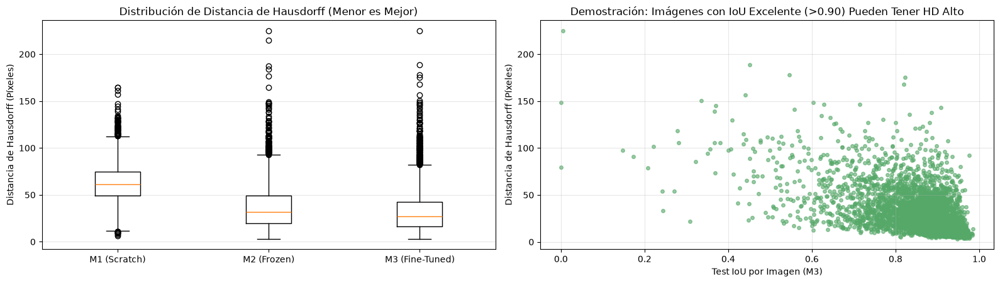

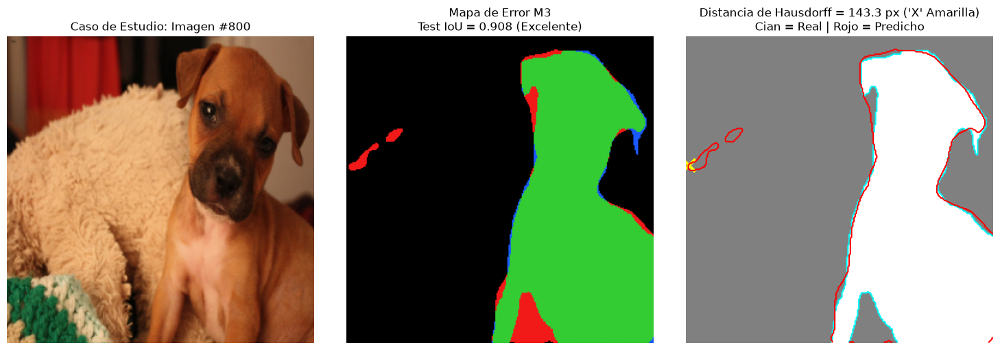

In [33]:
# Graficar distribuciones de HD y el caso de estudio de la discrepancia con IoU
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6)) 

# Diagrama de cajas (Boxplot) de HD por modelo
ax[0].boxplot([df_hd[df_hd.Modelo == k]["HD (px)"].dropna() for k in ["M1", "M2", "M3"]], tick_labels=["M1 (Scratch)", "M2 (Frozen)", "M3 (Fine-Tuned)"], showfliers=True) 
ax[0].set_ylabel("Distancia de Hausdorff (Píxeles)")
ax[0].set_title("Distribución de Distancia de Hausdorff (Menor es Mejor)")
ax[0].grid(axis="y", alpha=0.3)

# Scatter Plot de IoU vs. HD en el Modelo M3
d3_hd = df_hd[df_hd.Modelo == "M3"]  # M3
ax[1].scatter(d3_hd["IoU"], d3_hd["HD (px)"], s=16, alpha=0.6, color=COLORS["M3"])  # Scatter
ax[1].set_xlabel("Test IoU por Imagen (M3)")
ax[1].set_ylabel("Distancia de Hausdorff (Píxeles)")
ax[1].set_title("Demostración: Imágenes con IoU Excelente (>0.90) Pueden Tener HD Alto") 
ax[1].grid(alpha=0.3)
plt.tight_layout()
save_fig("inv5_hausdorff.png")
plt.show() 

# Encontrar e ilustrar el CASO CASO DE ESTUDIO: Imagen con IoU alto (>0.85) pero con HD maximo por una pequeña isla flotante
cand = d3_hd[d3_hd["IoU"] > 0.85].sort_values("HD (px)", ascending=False)  # Ordenar
worst_img = int(cand.iloc[0]["img"])  # Indice de la peor imagen



pb_w, gt_w = PROBS["M3"][worst_img] > 0.5, GTS[worst_img]  # Prediccion y GT
d_map = ndimage.distance_transform_edt(~contour(gt_w))  # Mapa de distancia al contorno real
far_pt = np.unravel_index(np.argmax(np.where(contour(pb_w), d_map, 0)), pb_w.shape)  # Punto mas lejano

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(denorm(test_ds[worst_img][0]))  # Imagen RGB
ax[0].set_title(f"Caso de Estudio: Imagen #{worst_img}")
ax[1].imshow(error_rgb(pb_w.astype(int), gt_w.astype(int)))  # Mapa de error
ax[1].set_title(f"Mapa de Error M3\nTest IoU = {iou_np(pb_w, gt_w):.3f} (Excelente)")
ax[2].imshow(gt_w, cmap="gray", alpha=0.5)  # GT
ax[2].contour(gt_w, levels=[0.5], colors="cyan", linewidths=1.5)  # Contorno real
ax[2].contour(pb_w, levels=[0.5], colors="red", linewidths=1.5)  # Contorno predicho
ax[2].scatter([far_pt[1]], [far_pt[0]], s=180, marker="x", color="yellow", linewidths=3)  # Marca 'X' amarilla en la falla HD
ax[2].set_title(f"Distancia de Hausdorff = {hausdorff(pb_w, gt_w)[0]:.1f} px ('X' Amarilla)\nCian = Real | Rojo = Predicho")
for a in ax:
    a.axis("off")
plt.tight_layout()
save_fig("inv5_ejemplo_hausdorff.png")
plt.show()

RESULTS["hausdorff"]["caso_estudio"] = {"img": worst_img, "iou": float(iou_np(pb_w, gt_w)), "hd_px": float(hausdorff(pb_w, gt_w)[0])}
save_results()

**Análisis Cualitativo del Error Geométrico Máximo:**
- A lo largo de la progresión de los modelos, se observa una reducción en las distancias de frontera peores casos (HD y HD95), reflejando una mejor alineación de los contornos predichos con respecto a la máscara de referencia.
- **Detección de Errores Locales:** La métrica de Hausdorff identifica imperfecciones o delaminaciones aisladas en la frontera de las predicciones que pasan inadvertidas para el IoU. 

**Tratamiento Matemático de Casos Límite (Máscaras Vacías):**
- Cabe destacar que la Distancia de Hausdorff se encuentra matemáticamente indeterminada en escenarios donde alguna de las máscaras (predicha o real) carece de contornos válidos (ausencia total de píxeles de primer plano). En la implementación práctica, dichos casos retornan valores no numéricos (), por lo que deben filtrarse adecuadamente al calcular estadísticas agregadas del conjunto de evaluación.

## **Resumen de Todas Las Preguntas De Investicación**

,Descripción Corta,Test IoU,Test Dice,Accuracy,Precisión,Recall,Tiempo (s)
Experimento,,,,,,,
M1,U-Net Baseline construida desde cero (BCEDiceLoss),0.5086,0.6742,0.8013,0.6632,0.6856,558.700000
M2,ResNetUNet con Encoder ResNet-18 Congelado,0.8426,0.9146,0.9494,0.9261,0.9033,233.200000
M3,ResNetUNet con Fine-Tuning End-to-End Complete,0.8619,0.9258,0.9554,0.9234,0.9283,241.800000
R1,U-Net Baseline entrenada puramente con BCEWithLogitsLoss sin Dice,0.5026,0.6690,0.7725,0.5934,0.7667,538.500000
R2,ResNetUNet con Encoder Congelado SIN Skip Connections,0.7260,0.8412,0.9058,0.8509,0.8318,214.400000
R4,ResNetUNet con Data Augmentation Médica Avanzada (Deformación Elástica + Gamma),0.8471,0.9172,0.9496,0.9036,0.9312,260.100000


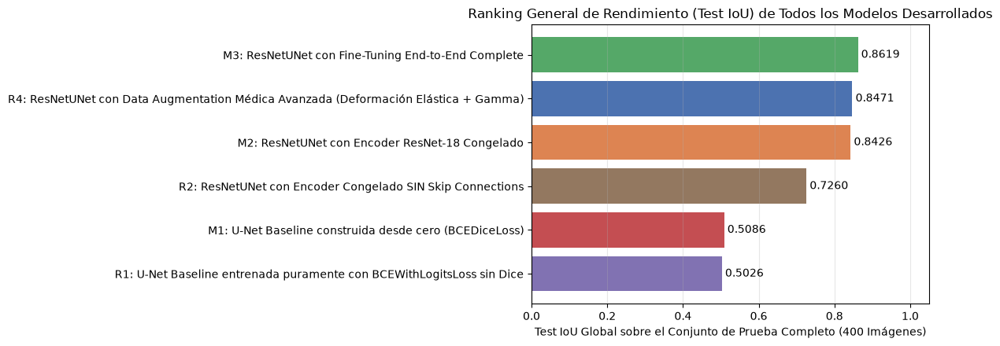

In [34]:
# Tabla combinando los 6 experimentos ejecutados en el laboratorio
summary_rows = []  # Lista de filas

exp_list = [ 
    ("M1", "U-Net Baseline construida desde cero (BCEDiceLoss)"), 
    ("M2", "ResNetUNet con Encoder ResNet-18 Congelado"),
    ("M3", "ResNetUNet con Fine-Tuning End-to-End Complete"),
    ("R1", "U-Net Baseline entrenada puramente con BCEWithLogitsLoss sin Dice"), 
    ("R2", "ResNetUNet con Encoder Congelado SIN Skip Connections"),
    ("R4", "ResNetUNet con Data Augmentation Médica Avanzada (Deformación Elástica + Gamma)") 
]

for k, desc in exp_list:  # Recorrer
    t_data = RESULTS[k]["test"]  # Extraer datos de test
    summary_rows.append({
        "Experimento": k,
        "Descripción Corta": desc,
        "Test IoU": t_data["iou"],
        "Test Dice": t_data["dice"],
        "Accuracy": t_data["acc"],
        "Precisión": t_data["precision"],
        "Recall": t_data["recall"], 
        "Tiempo (s)": round(RESULTS[k]["time"], 1) 
    }) 

df_all = pd.DataFrame(summary_rows).set_index("Experimento")  # DataFrame final
df_all.to_csv(METRIC_DIR / "resumen_experimentos.csv")
save_results() 

display(df_all.style.format({c: "{:.4f}" for c in ["Test IoU", "Test Dice", "Accuracy", "Precisión", "Recall"]}).background_gradient(subset=["Test IoU", "Test Dice"], cmap="Greens")) 

# Graficar el ranking completo de IoU
fig, ax = plt.subplots(figsize=(12, 4.5))
order = df_all.sort_values("Test IoU").index  # Ordenar de menor a mayor
b_rank = ax.barh([f"{k}: {df_all.loc[k, 'Descripción Corta']}" for k in order], df_all.loc[order, "Test IoU"], color=[COLORS[k] for k in order])
ax.bar_label(b_rank, fmt="%.4f", padding=3)  # Anotacion
ax.set_xlim(0, 1.05)
ax.set_xlabel("Test IoU Global sobre el Conjunto de Prueba Completo (Test Set Completo Oficial)")
ax.set_title("Ranking General de Rendimiento (Test IoU) de Todos los Modelos Desarrollados")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
save_fig("resumen_ranking.png") 
plt.show()

## **Conclusiones**

Las salidas guardadas de una ejecución anterior muestran IoU 0.5086 y Dice 0.6742 para M1, y 0.8426 y 0.9146 para M2. Estas cifras describen aquella corrida, no la evaluación actual sobre las 3,669 imágenes del test oficial: los experimentos todavía deben volver a ejecutarse con el loader actualizado. En esa corrida anterior, la diferencia entre M1 y M2 fue grande y es consistente con que el encoder preentrenado ayudara al modelo, pero no permite asegurar que ocurra igual con cualquier conjunto o configuración.

En esas mismas salidas anteriores, M3 llegó a IoU 0.8619 y Dice 0.9258. La diferencia frente a M2 fue más pequeña que la observada entre M1 y M2. Con una sola corrida de cinco épocas no se puede decir que el fine-tuning siempre sea mejor, y esos números deben actualizarse antes de reportar resultados sobre el test oficial completo.

Las salidas anteriores también muestran una diferencia entre R2, sin *skip connections* (IoU 0.7260, Dice 0.8412), y M2 (0.8426, 0.9146). Esto respalda su utilidad en esta U-Net; las visualizaciones ayudan a ver cómo cambia el contorno, pero no prueban que sean indispensables en toda arquitectura. Hay que recalcular la comparación con la partición de test completa.

En las salidas guardadas, M1 (BCE + Dice) obtuvo IoU 0.5086, Dice 0.6742, precisión 0.6632 y recall 0.6856. R1 (solo BCE) obtuvo 0.5026, 0.6690, 0.5934 y 0.7667, respectivamente. En esa corrida, la BCE sola tuvo menor precisión y mayor recall; las diferencias de IoU y Dice fueron pequeñas. No basta este resultado para atribuir el cambio únicamente a la función de pérdida sin repetir el entrenamiento bajo varias semillas.

La tabla de Hausdorff guardada da otra perspectiva: M3 tuvo HD promedio de 32.974 píxeles y HD95 promedio de 22.137, menores que los de M2 (37.421 y 26.169) y M1 (62.597 y 52.741). Son distancias en píxeles a la resolución evaluada y complementan —no reemplazan— IoU y Dice; también deben recalcularse con el test completo.

Por último, R4 aplica aumentación inspirada en imágenes médicas a imágenes de mascotas. Puede servir para estudiar perturbaciones geométricas y de intensidad, pero estos resultados no demuestran robustez ante escáneres ni que el método vaya a funcionar en datos médicos. Para sostener esa conclusión haría falta evaluarlo en datos del dominio correspondiente. En resumen, las métricas citadas son históricas; vuelve a ejecutar los experimentos sobre las 3,669 imágenes oficiales antes de presentar una conclusión sobre el test completo. Para elegir el umbral, usa validación y deja el test solo para la evaluación final.